In [1]:
# import section
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st
import pathlib
import json
import string
import re
import copy

In [2]:
# options section
pd.set_option('display.float_format', '{:G}'.format)
plt.rcParams['savefig.dpi'] = 300

In [3]:
START = pathlib.Path.home() / 'Desktop' / 'uni' / 'tirocinio'
EMISSIONS = START / 'energy_measurements'
GEN_PATH = EMISSIONS / 'test_gen_energy_measurements.csv'
EXEC_PATH = EMISSIONS / 'test_exec_energy_measurements.csv'
REPORTS = START / 'reports'
STATISTICS_PATH = REPORTS / 'pynguin' / 'statistics.csv'
COVERAGE_PATH = REPORTS / 'coverage'
ITERATIONS = 3
ALGORITHMS = ['DYNAMOSA',
              'MOSA',
              'MIO',
              'WHOLE_SUITE',
              'RANDOM_TEST_CASE_SEARCH',
              'RANDOM_TEST_SUITE_SEARCH',
              'WHOLE_SUITE_ENERGY_AWARE',
              'MIO_ENERGY_AWARE',
              'WHOLE_SUITE_ENERGY_AWARE_ALT',
              'MIO_ENERGY_AWARE_ALT'
             ]
ALGORITHM_FORMATTER = {'DYNAMOSA': 'DMOSA',
                       'MOSA': 'MOSA',
                       'MIO': 'MIO',
                       'WHOLE_SUITE': 'WS',
                       'RANDOM_TEST_CASE_SEARCH': 'RTCS',
                       'RANDOM_TEST_SUITE_SEARCH': 'RTSS',
                       'WHOLE_SUITE_ENERGY_AWARE': r'$\text{WS}_\text{EA}$',
                       'MIO_ENERGY_AWARE': r'$\text{MIO}_\text{EA}$',
                       'WHOLE_SUITE_ENERGY_AWARE_ALT': r"$\text{WS}_{\text{EA}'}$",
                       'MIO_ENERGY_AWARE_ALT': r"$\text{MIO}_{\text{EA}'}$"
                      }
COVERAGES_PATHS = {algorithm: [COVERAGE_PATH / algorithm / f'iteration_{i}' / 'cov_report.json' for i in range(1,ITERATIONS+1)] for algorithm in ALGORITHMS}
IMAGES_PATH = START / 'jupyter' / 'images'

In [4]:
def import_and_fix_emissions_file(data_path):
    EMISSIONS_TYPES = {'cloud_provider': 'str',
                       'cloud_region': 'str',
                       'on_cloud': 'bool'
                      }
    EMISSIONS_ARGS = {'index_col': 'timestamp',
                      'dtype': EMISSIONS_TYPES,
                      'true_values': ['Y'],
                      'false_values': ['N'],
                      'parse_dates': ['timestamp']
                     }
    INDEX_NAMES = {'timestamp' : 'Data e ora'
                  }
    COLUMN_NAMES = {'project_name': 'Progetto',
                    'run_id': 'Id della run',
                    'experiment_id': 'Id dell\'esperimento',
                    'duration': 'Durata (s)',
                    'emissions': 'Emissioni (kg CO2eq)',
                    'emissions_rate': 'Tasso di emissioni (kg/s)',
                    'cpu_power': 'Potenza della CPU (W)',
                    'gpu_power': 'Potenza della GPU (W)',
                    'ram_power': 'Potenza della RAM (W)',
                    'cpu_energy': 'Energia usata per CPU (kWh)',
                    'gpu_energy': 'Energia usata per GPU (kWh)',
                    'ram_energy': 'Energia usata per RAM (kWh)',
                    'energy_consumed': 'Totale energia consumata (kWh)',
                    'water_consumed': 'Acqua consumata (L)',
                    'country_name': 'Nazione',
                    'country_iso_code': 'Codice ISO nazione',
                    'region': 'Regione',
                    'on_cloud': 'Sul cloud',
                    'cloud_provider': 'Cloud provider',
                    'cloud_region': 'Regione cloud',
                    'os': 'Sistema operativo',
                    'python_version': 'Versione di Python',
                    'codecarbon_version': 'Versione di CodeCarbon',
                    'cpu_count': 'Numero di CPU',
                    'cpu_model': 'Modello della CPU',
                    'gpu_count': 'Numero di GPU',
                    'gpu_model': 'Modello della GPU',
                    'longitude': 'Longitudine',
                    'latitude': 'Latitudine',
                    'ram_total_size': 'RAM totale disponibile (GB)',
                    'tracking_mode': 'Modalità di tracciamento',
                    'cpu_utilization_percent': 'Media utilizzazione CPU (%)',
                    'gpu_utilization_percent': 'Media utilizzazione GPU (%)',
                    'ram_utilization_percent': 'Media utilizzazione RAM (%)',
                    'ram_used_gb': 'Media RAM usata durante il tracciamento (GB)',
                    'pue': 'PUE',
                    'wue': 'WUE (L/kWh)'
                   }  
    df = pd.read_csv(data_path, **EMISSIONS_ARGS) \
           .rename(columns=COLUMN_NAMES) \
           .rename_axis(index=INDEX_NAMES)
    df = split_project_name_into_two_columns(df, ALGORITHMS)
    return df

def split_project_name_into_two_columns(df, algorithms):
    pattern = r'(.*)_(' + '|'.join([alg for alg in algorithms][::-1]) + ')'
    df[['Progetto', 'Algoritmo']] = df['Progetto'].str.extract(pattern)
    return df

gen_data = import_and_fix_emissions_file(GEN_PATH)
exec_data = import_and_fix_emissions_file(EXEC_PATH)

In [5]:
def calculate_emissions_mean(df):
    # group by and calculate the mean of relevant columns
    group = df.groupby(by=['Progetto', 'Algoritmo'])[['Durata (s)',
                                                      'Emissioni (kg CO2eq)',
                                                      'Tasso di emissioni (kg/s)',
                                                      'Potenza della CPU (W)',
                                                      'Potenza della GPU (W)',
                                                      'Potenza della RAM (W)',
                                                      'Energia usata per CPU (kWh)',
                                                      'Energia usata per GPU (kWh)',
                                                      'Energia usata per RAM (kWh)',
                                                      'Totale energia consumata (kWh)',
                                                      'Media utilizzazione CPU (%)',
                                                      'Media utilizzazione GPU (%)',
                                                      'Media utilizzazione RAM (%)',
                                                      'Media RAM usata durante il tracciamento (GB)'
                                                     ]].mean()
    return group

fixed_gen = calculate_emissions_mean(gen_data)
fixed_exec = calculate_emissions_mean(exec_data)

In [6]:
def import_and_fix_statistics_file(data_path):
    STATISTICS_TYPES = {'SearchTime': 'float64',
                        'TotalTime': 'float64',
                        'Goals': pd.Int64Dtype()
                       }
    STATISTICS_COLUMNS = {'ProjectName': 'Progetto',
                          'TargetModule': 'Modulo',
                          'SearchTime': 'Tempo di ricerca (s)',
                          'TotalTime': 'Tempo totale (s)',
                          'BranchCoverage': 'Copertura delle ramificazioni (%)',
                          'Coverage': 'Copertura (%)',
                          'RandomSeed': 'Seed',
                          'AlgorithmIterations': 'Numero iterazioni effettuate',
                          'Goals': 'Numero di goal',
                          'MutationScore': 'Punteggio di mutazione',
                          'Fitness': 'Valore di fitness del miglior individuo'
                         }
    df = pd.read_csv(data_path, dtype=STATISTICS_TYPES) \
           .rename(columns=STATISTICS_COLUMNS)
    # initially seconds are measured in nanoseconds and the coverages are values between 0 and 1
    df[['Tempo di ricerca (s)', 'Tempo totale (s)']] *= 1e-9
    df[['Copertura delle ramificazioni (%)', 'Copertura (%)']] *= 100
    df = split_project_name_into_two_columns(df, ALGORITHMS)
    return df
statistics_data = import_and_fix_statistics_file(STATISTICS_PATH)

In [7]:
def calculate_statistics_mean(df):
    # group by and calculate the mean of relevant columns
    group = df.groupby(by=['Progetto', 'Modulo', 'Algoritmo'])[['Tempo di ricerca (s)',
                                                               'Tempo totale (s)',
                                                               'Copertura delle ramificazioni (%)',
                                                               'Copertura (%)',
                                                               'Punteggio di mutazione',
                                                               'Valore di fitness del miglior individuo'
                                                              ]].mean()
    return group

fixed_statistics = calculate_statistics_mean(statistics_data)

In [8]:
def create_coverage_tables(report_paths, algorithms): 
    result = {}
    tables = {}
    result['totals'] = {}
    result['summary'] = {}
    COLUMNS = {'covered_lines': 'Righe di codice coperte',
               'num_statements': 'Numero totale di istruzioni',
               'percent_covered': 'Copertura totale (%)',
               'percent_covered_display': 'Copertura totale visualizzata',
               'missing_lines': 'Righe di codice mancanti',
               'excluded_lines': 'Righe di codice escluse',
               'percent_statements_covered': 'Copertura delle istruzioni (%)',
               'percent_statements_covered_display': 'Copertura delle istruzioni visualizzata',
               'num_branches': 'Numero totale di ramificazioni',
               'num_partial_branches': 'Ramificazioni parzialmente coperte',
               'covered_branches': 'Ramificazioni coperte',
               'missing_branches': 'Ramificazioni mancanti',
               'percent_branches_covered': 'Copertura delle ramificazioni (%)',
               'percent_branches_covered_display': 'Copertura delle ramificazioni visualizzata'
              }
    for algorithm in algorithms:
        for idx, iter_path in enumerate(report_paths[algorithm]):
            with iter_path.open() as file:
                data = json.load(file)
                result['totals'][(algorithm,idx+1)] = data['totals']
                for module in data['files']:
                    result['summary'][(idx+1,algorithm,module)] = data['files'][module]['summary']
    tables['totals'] = pd.DataFrame.from_dict(result['totals'], orient='index') \
                                  .rename_axis(['Algoritmo', 'Iterazione']) \
                                  .rename(columns=COLUMNS) \
                                  .drop(columns=['Copertura totale visualizzata',
                                                 'Copertura delle istruzioni visualizzata',
                                                 'Copertura delle ramificazioni visualizzata'
                                                ])
    tables['summary'] = pd.DataFrame.from_dict(result['summary'], orient='index') \
                                    .rename_axis(['Iterazione', 'Algoritmo', 'Modulo']) \
                                    .rename(columns=COLUMNS) \
                                    .drop(columns=['Copertura totale visualizzata',
                                                   'Copertura delle istruzioni visualizzata',
                                                   'Copertura delle ramificazioni visualizzata'
                                                  ])
    # extracts the projects that will be used for a new level of the index
    tables['summary'].reset_index(inplace=True)
    tables['summary']['Progetto'] = tables['summary']['Modulo'].map(lambda x: x.split('/')[2])
    tables['summary'].set_index(keys=['Algoritmo', 'Iterazione', 'Progetto', 'Modulo'], inplace=True)
    return tables

fixed_coverages = create_coverage_tables(COVERAGES_PATHS, ALGORITHMS)
fixed_totals = fixed_coverages['totals']
fixed_summary = fixed_coverages['summary']

In [9]:
summary_coverage_means = fixed_summary.groupby(['Algoritmo', 'Progetto', 'Modulo'])[['Copertura totale (%)',
                                                                                     'Copertura delle istruzioni (%)',
                                                                                     'Copertura delle ramificazioni (%)']].mean()

In [10]:
# join of some tables which might be useful for later
def join_emissions_statistics(df):
    return df.join(fixed_statistics.reset_index('Modulo'),
                   on=['Progetto', 'Algoritmo'],
                   how='outer') \
             .set_index(keys=[fixed_gen.index, 'Modulo'])

In [11]:
gen_statistics = join_emissions_statistics(fixed_gen)

In [12]:
exec_statistics = join_emissions_statistics(fixed_exec)

In [13]:
stats_summary = fixed_statistics.reset_index() \
                                .merge(summary_coverage_means.reset_index(),
                                       on=['Algoritmo','Progetto'],
                                       how='inner',
                                       suffixes=(' secondo Pynguin','')) \
                                .set_index(['Progetto', 'Modulo secondo Pynguin', 'Algoritmo']) \
                                .rename_axis(index={'Modulo secondo Pynguin': 'Modulo'})

In [14]:
def join_emissions_summary(df):
    return df.join(summary_coverage_means.reset_index('Modulo'),
                   on=['Algoritmo', 'Progetto'],
                   how='inner')

In [15]:
gen_summary = join_emissions_summary(fixed_gen)

In [16]:
exec_summary = join_emissions_summary(fixed_exec)

In [17]:
# What this function does is get the max (or min) of a certain column per algorithm and put the name of that module next to the value
def get_info_per_algorithm(df, column, want_max=True):
    (f, idx_f) = (pd.api.typing.DataFrameGroupBy.max, pd.api.typing.DataFrameGroupBy.idxmax) \
                 if want_max \
                 else (pd.api.typing.DataFrameGroupBy.min, pd.api.typing.DataFrameGroupBy.idxmin)
    a = f(df.groupby(by='Algoritmo'))
    b = idx_f(df.groupby(by='Algoritmo')).apply(lambda x: x.str[2])
    return a.join(b, lsuffix='', rsuffix='_b') \
            .rename(columns={column + '_b': 'Modulo'})[['Modulo', column]]

def get_info_of_category(data, category, subcategory, subsubcategory):
    tmp1 = data[category][subcategory][subsubcategory].reset_index()
    tmp2 = tmp1[subsubcategory]
    f = pd.Series.max if subcategory == 'max' else pd.Series.min 
    return tmp1[tmp2 == f(tmp2)]

In [18]:
# Get the relevant information for each type of emission data frame
INFO_CATEGORY = {'Durata (s)', 'Totale energia consumata (kWh)'}
info = {'gen': {'max': {},
                'min': {}
               },
        'exec': {'max': {},
                 'min': {}
                }
       }
for cat in info:
    df = gen_statistics if cat == 'gen' else exec_statistics
    # assume that both gen and exec data frames have the same structure
    df = df[fixed_gen.columns]
    for subcat in info[cat]:
        for subsubcat in INFO_CATEGORY:
            info[cat][subcat][subsubcat] = get_info_per_algorithm(df, subsubcat, subcat == 'max')

In [19]:
# Data frames that will (maybe) be used:
# fixed_gen
# fixed_exec
# fixed_statistics
# fixed_totals
# fixed_summary
# gen_statistics
# exec_statistics
# stats_summary
# gen_summary
# exec_summary
# gen_exec

def put_algorithm_annotation(ax):
    TEXT = \
fr'''
    Nota:
        • DMOSA: {pretty_algorithm('DYNAMOSA')}
        • $\text{{MIO}}_\text{{EA}}$: {pretty_algorithm('MIO_ENERGY_AWARE')}    
        • $\text{{MIO}}_{{\text{{EA}}'}}$: {pretty_algorithm('MIO_ENERGY_AWARE_ALT')}    
        • RTCS: {pretty_algorithm('RANDOM_TEST_CASE_SEARCH')}    
        • RTSS: {pretty_algorithm('RANDOM_TEST_SUITE_SEARCH')}    
        • WS: {pretty_algorithm('WHOLE_SUITE')}    
        • $\text{{WS}}_\text{{EA}}$: {pretty_algorithm('WHOLE_SUITE_ENERGY_AWARE')}    
        • $\text{{WS}}_{{\text{{EA}}'}}$: {pretty_algorithm('WHOLE_SUITE_ENERGY_AWARE_ALT')}    
'''
    BBOX_ARGS={'boxstyle': 'Round',
               'facecolor': 'Cyan',
               'alpha': 0.2,
               'edgecolor': 'Black'
              }
    return ax.annotate(TEXT, (370,120), xycoords='axes points', bbox=BBOX_ARGS)
    
# for the generation data and execution data create boxplots this way
def boxplot_of_algorithms(data, column, log_scale=False, title=None):
    ax = sns.boxplot(data=data,
                     x='Algoritmo',
                     y=column,
                     log_scale=log_scale,
                     color='orange',
                     formatter=ALGORITHM_FORMATTER)
    sns.despine(ax=ax, top=True, right=True)
    ax.set_title(title)
    # put_algorithm_annotation(ax)
    return ax

# Return the stylized name of the algorithms
def pretty_algorithm(algorithm):
    match algorithm:
        case 'DYNAMOSA':
            return 'DynaMOSA'
        case 'MOSA' | 'MIO':
            return algorithm
        case 'WHOLE_SUITE' | 'RANDOM_TEST_CASE_SEARCH' | 'RANDOM_TEST_SUITE_SEARCH':
            return string.capwords(algorithm.replace('_', ' '), sep=' ')
        case 'MIO_ENERGY_AWARE' | 'WHOLE_SUITE_ENERGY_AWARE':
            return ''.join((pretty_algorithm(algorithm[:-13]), string.capwords(algorithm[-13:].replace('_', ' '), sep=' ')))
        case 'WHOLE_SUITE_ENERGY_AWARE_ALT' | 'MIO_ENERGY_AWARE_ALT':
            return pretty_algorithm(algorithm[:-4]) + ' (versione alternativa)'
        case _:
            raise ValueError(f'{algorithm} not recognized as an algorithm.')

def put_max_min_annotation(ax, info, cat, column, max_pos, min_pos):
    for subcat in info[cat]:
        cat_info = get_info_of_category(info, cat, subcat, column)
        module = cat_info['Modulo'].values[0]
        algorithm_position = cat_info.index[0]
        value_position = cat_info[column].values[0]
        pos = max_pos if subcat == 'max' else min_pos
        arrow_args = {'arrowstyle': '-|>',
                      'edgecolor': mpl.color_sequences['tab10'][0]
                     }
        ax.annotate(module,
                    xy=(algorithm_position, value_position),
                    xycoords='data',
                    xytext=pos,
                    textcoords='offset points',
                    arrowprops=arrow_args)

# Only shows the ticks which are in half of the current power of 10
def log_format(lower, upper, scientific):
    def f(x,pos):
        for i in range(lower,upper+1):
            if 10**(i-1) < x < 10**i and x % (5 * 10**(i-1)) == 0:
                return x if not scientific else fr'${int(x*10**(-i+1))} \times 10^{{{i-1}}}$'
    return f

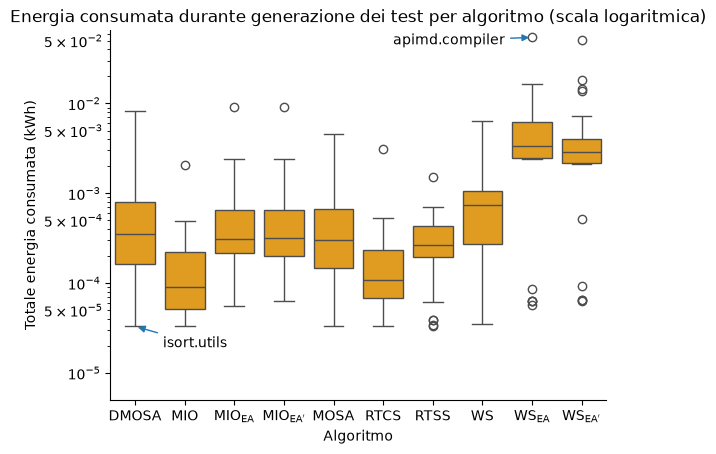

In [20]:
# Plot time
ax = boxplot_of_algorithms(fixed_gen,
                           'Totale energia consumata (kWh)',
                           log_scale=True,
                           title='Energia consumata durante generazione dei test per algoritmo (scala logaritmica)')
put_max_min_annotation(ax, info, 'gen', 'Totale energia consumata (kWh)', (-100,-5), (20,-15))
ax.set(ylim=(0.5e-5,6.5e-2))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1,)))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation())
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator([i * 10**j for i in range(2,10) for j in range(-2,-6,-1)]))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(log_format(-5,-1, True)))
ax.get_figure().savefig(IMAGES_PATH / 'box_gen_energy.jpg', bbox_inches='tight')

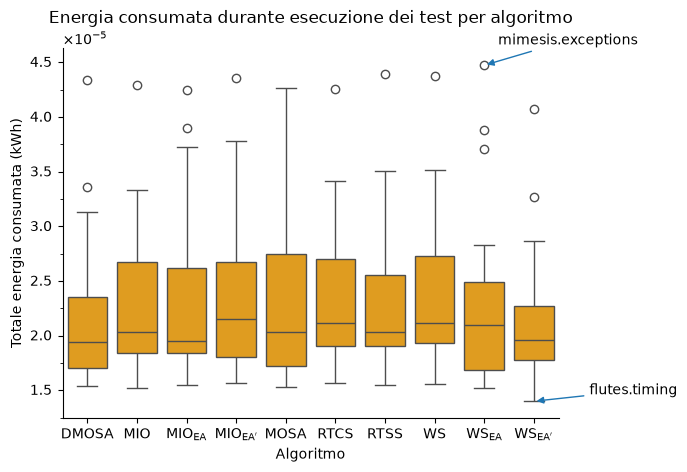

In [21]:
ax = boxplot_of_algorithms(fixed_exec,
                          'Totale energia consumata (kWh)',
                          log_scale=False,
                          title='Energia consumata durante esecuzione dei test per algoritmo')
put_max_min_annotation(ax, info, 'exec', 'Totale energia consumata (kWh)', (10,15), (40,5))
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(1e-5,5e-5,0.25e-5)))
ax.get_figure().savefig(IMAGES_PATH / 'box_exec_energy.jpg', bbox_inches='tight')

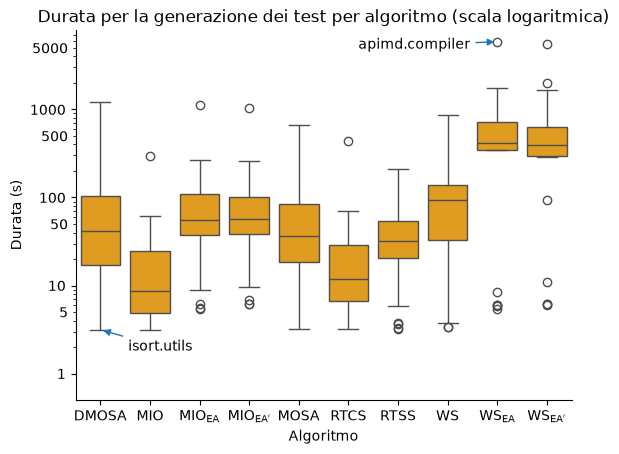

In [22]:
ax = boxplot_of_algorithms(fixed_gen,
                           'Durata (s)',
                           log_scale=True,
                           title='Durata per la generazione dei test per algoritmo (scala logaritmica)')
put_max_min_annotation(ax, info, 'gen', 'Durata (s)', (-100,-5), (20,-15))
ax.set(ylim=(0.5,7.9e3))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1,)))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatter())
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator([i * 10**j for i in range(2,10) for j in range(0,4)]))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(log_format(1,4,False)))
ax.get_figure().savefig(IMAGES_PATH / 'box_gen_time.jpg', bbox_inches='tight')

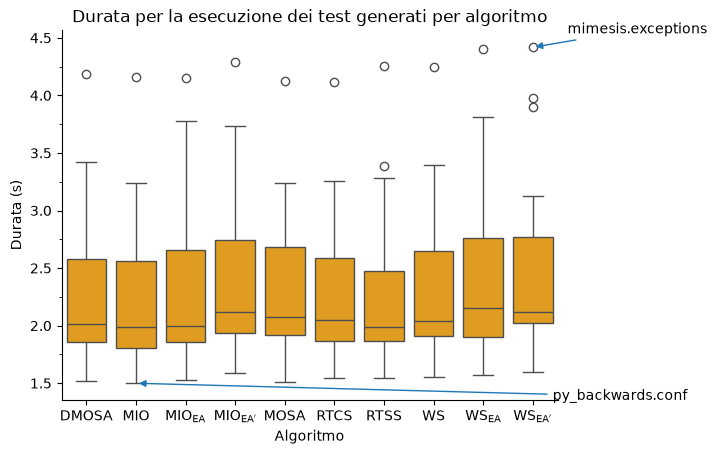

In [23]:
ax = boxplot_of_algorithms(fixed_exec,
                           'Durata (s)',
                           log_scale=False,
                           title='Durata per la esecuzione dei test generati per algoritmo')
put_max_min_annotation(ax, info, 'exec', 'Durata (s)', (25,10), (300,-12))
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(1.5,5,0.25)))
ax.get_figure().savefig(IMAGES_PATH / 'box_exec_time.jpg', bbox_inches='tight')

In [24]:
def coverage_of_algorithms(data, column, padding=0, title=None):
    ax = sns.barplot(data,
                     x='Algoritmo',
                     y=column,
                     order=sorted(set(data.index.get_level_values(0))),
                     formatter=ALGORITHM_FORMATTER,
                     errorbar=('sd', 1))
    sns.despine(ax=ax, top=True, right=True)
    ax.set(title=title, ylim=(0,105), yticks=range(0,110,10))
    ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(range(5,96,5)))
    ax.bar_label(ax.containers[0], padding=padding, fmt='%.2f')
    # annotation = put_algorithm_annotation(ax)
    return ax

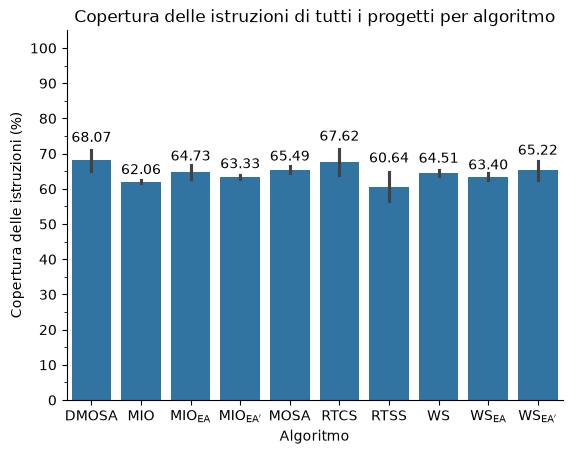

In [25]:
ax = coverage_of_algorithms(fixed_totals,
                            'Copertura delle istruzioni (%)',
                            [11,3,6,4,4,13,15,5,3,9],
                            'Copertura delle istruzioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_statements.jpg', bbox_inches='tight')

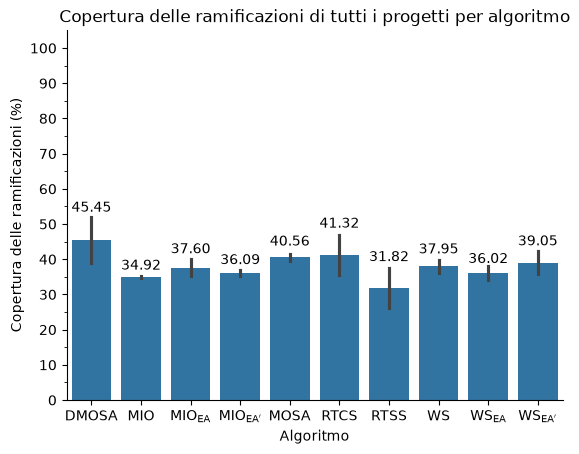

In [26]:
ax = coverage_of_algorithms(fixed_totals,
                            'Copertura delle ramificazioni (%)',
                            [18,3,8,4,6,17,17,7,5,10],
                            'Copertura delle ramificazioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_branches.jpg', bbox_inches='tight')

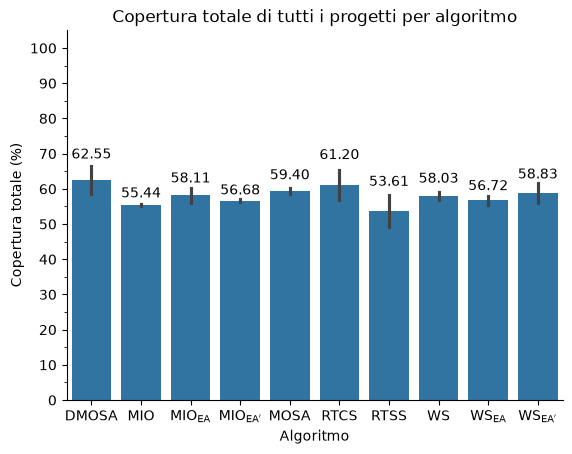

In [27]:
ax = coverage_of_algorithms(fixed_totals,
                            'Copertura totale (%)',
                            padding=[13,3,7,2,6,16,16,7,5,8],
                            title='Copertura totale di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_total.jpg', bbox_inches='tight')

In [28]:
def abbr_algorithm(algorithm):
    match algorithm:
        case 'DYNAMOSA':
            return 'DMOSA'
        case 'MOSA' | 'MIO':
            return algorithm
        case 'WHOLE_SUITE' | 'RANDOM_TEST_CASE_SEARCH' | 'RANDOM_TEST_SUITE_SEARCH':
            return ''.join(map(lambda x: x[0], algorithm.split('_')))
        case 'WHOLE_SUITE_ENERGY_AWARE' | 'MIO_ENERGY_AWARE':
            return fr'$\text{{{abbr_algorithm(algorithm[:-13])}}}_\text{{EA}}$'
        case 'WHOLE_SUITE_ENERGY_AWARE_ALT' | 'MIO_ENERGY_AWARE_ALT':
            return fr"$\text{{{abbr_algorithm(algorithm[:-17])}}}_{{\text{{EA}}'}}$"
        case _:
            raise ValueError(f'{algorithm} not recognized as an algorithm.')

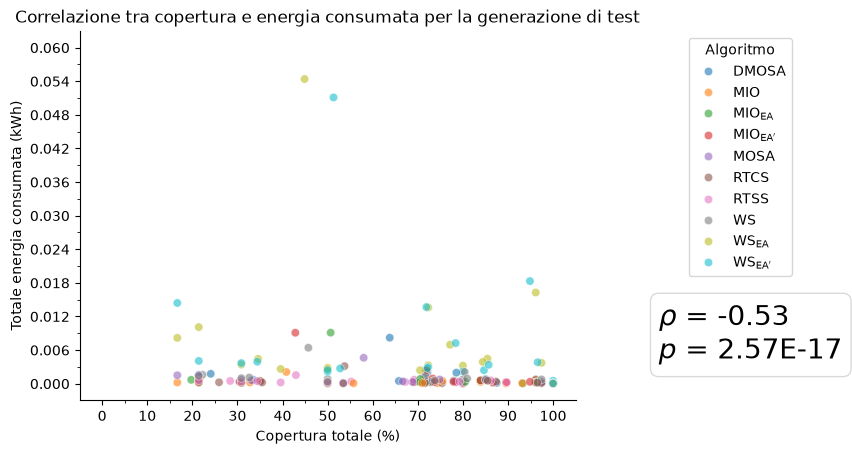

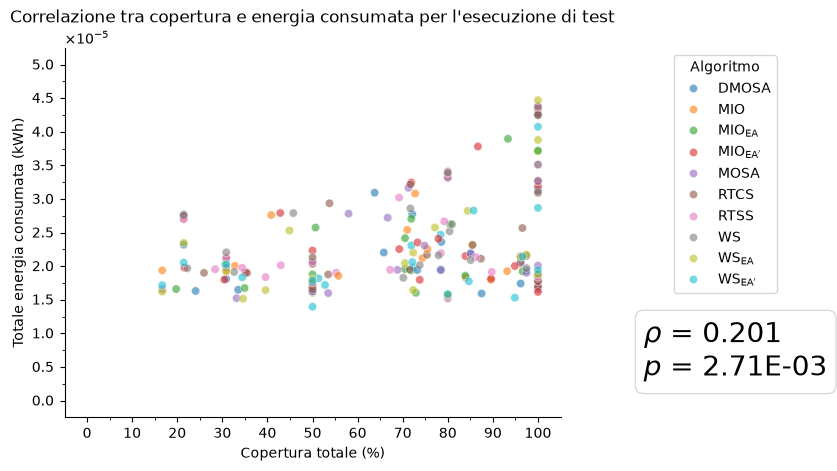

In [29]:
# x and y are the columns chosen, xspace and yspace are for extra spaces for the respective columna to add so that the points aren't cut
def plot_with_algorithms_and_regression(data, x, y, xlim, ylim, xspace, yspace, xticks_num, yticks_num, title, linregression=True, pearson=True):
    if linregression:
        sns.regplot(data, x=x, y=y, scatter=False, line_kws={'alpha': 0.4})
    r, p = st.pearsonr(x=data[x], y=data[y]) if pearson else st.spearmanrho(x=data[x], y=data[y])
    correlation = 'r' if pearson else r'\rho'
    ax = sns.scatterplot(data,
                         x=x,
                         y=y,
                         hue='Algoritmo',
                         alpha=0.6)
    sns.despine(ax=ax, top=True, right=True)
    ax.set(xlim=(xlim[0]-xspace, xlim[1]+xspace),
           xticks=np.linspace(xlim[0], xlim[1], xticks_num),
           ylim=(ylim[0]-yspace, ylim[1]+yspace),
           yticks=np.linspace(ylim[0], ylim[1], yticks_num),
           title=title)
    # Add minor locators at the middle of each tick
    ax.xaxis.set_minor_locator(mpl.ticker.FixedLocator(np.linspace(xlim[0]+xspace, xlim[1]-xspace, xticks_num-1)))
    ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.linspace(ylim[0]+yspace, ylim[1]-yspace, yticks_num-1)))
    sns.move_legend(ax, 'upper right', bbox_to_anchor=(1.45,1))
    # Format the algorithm names so that they are stylized properly and not in SCREAMING_SNAKE_CASE
    for text in ax.get_legend().get_texts():
        # text.set_text(pretty_algorithm(text.get_text()))
        text.set_text(abbr_algorithm(text.get_text()))
    # And now add the correlation coefficient and its p-value to the plot
    text = fr'''${correlation}$ = {r:.3G}
$p$ = {p:.2E}'''
    BBOX_ARGS={'boxstyle': 'Round',
               'facecolor': 'White',
               'edgecolor': 'Black',
               'alpha': 0.15,
              }
    ax.annotate(text, xy=(417,30), xycoords='axes points', bbox=BBOX_ARGS, fontsize=20)
    return ax

# Now actually do the plot
ax = plot_with_algorithms_and_regression(gen_summary,
                                         'Copertura totale (%)',
                                         'Totale energia consumata (kWh)',
                                         (0,100),
                                         (0,0.06),
                                         5,
                                         0.003,
                                         11,
                                         11,
                                         'Correlazione tra copertura e energia consumata per la generazione di test',
                                         linregression=False,
                                         pearson=False)
ax.get_figure().savefig(IMAGES_PATH / 'scatter_gen_coverage_energy.jpg', bbox_inches='tight')
plt.show()
ax = plot_with_algorithms_and_regression(exec_summary,
                                         'Copertura totale (%)',
                                         'Totale energia consumata (kWh)',
                                         (0,100),
                                         (0,5e-5),
                                         5,
                                         2.5e-6,
                                         11,
                                         11,
                                         'Correlazione tra copertura e energia consumata per l\'esecuzione di test',
                                         linregression=False,
                                         pearson=False)
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax.get_figure().savefig(IMAGES_PATH / 'scatter_exec_coverage_energy.jpg', bbox_inches='tight')

In [30]:
# What this function does is get the max (or min) of a certain column per algorithm and put the name of that module next to the value
def get_info_per_algorithm(df, column, want_max=True):
    (f, idx_f) = (pd.api.typing.DataFrameGroupBy.max, pd.api.typing.DataFrameGroupBy.idxmax) \
                 if want_max \
                 else (pd.api.typing.DataFrameGroupBy.min, pd.api.typing.DataFrameGroupBy.idxmin)
    a = f(df.groupby(by='Algoritmo'))
    b = idx_f(df.groupby(by='Algoritmo')).apply(lambda x: x.str[2])
    return a.join(b, lsuffix='', rsuffix='_b') \
            .rename(columns={column + '_b': 'Modulo'})[['Modulo', column]]


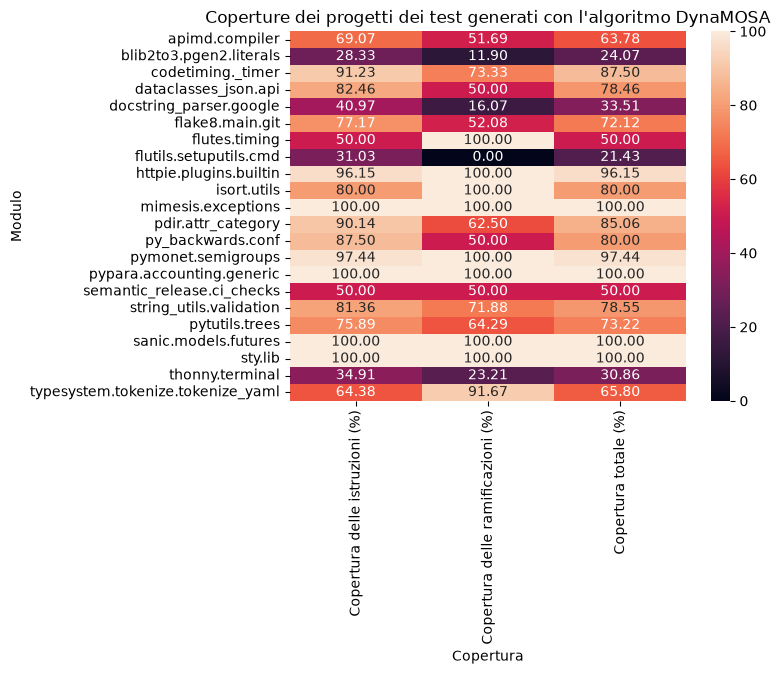

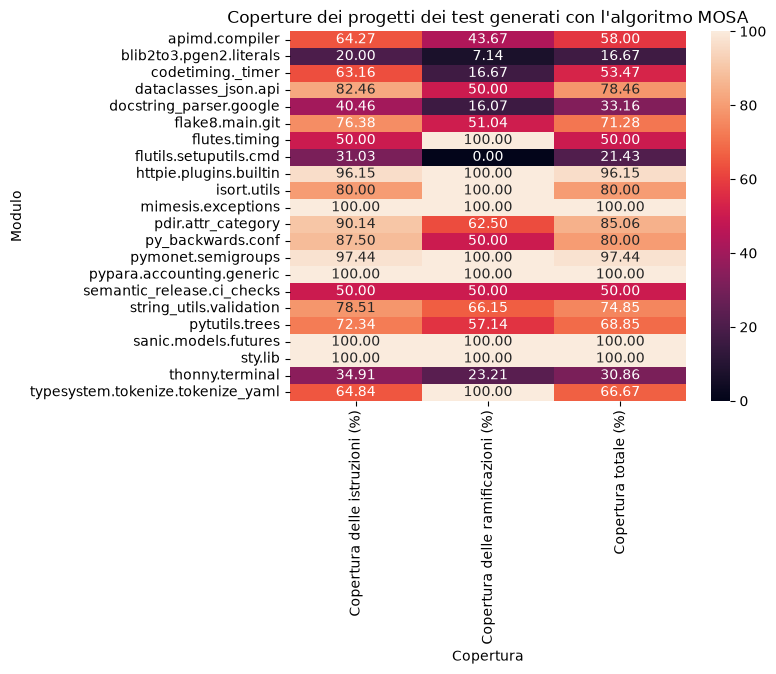

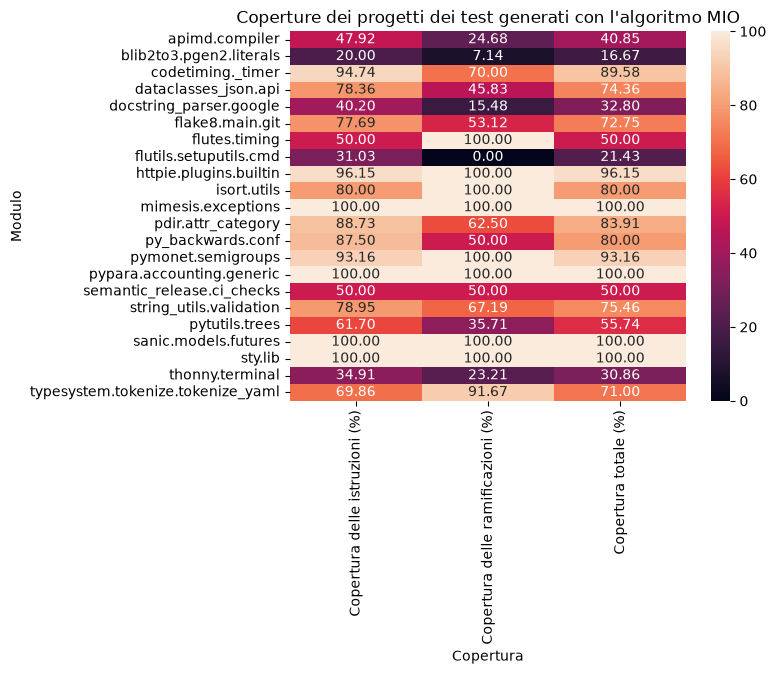

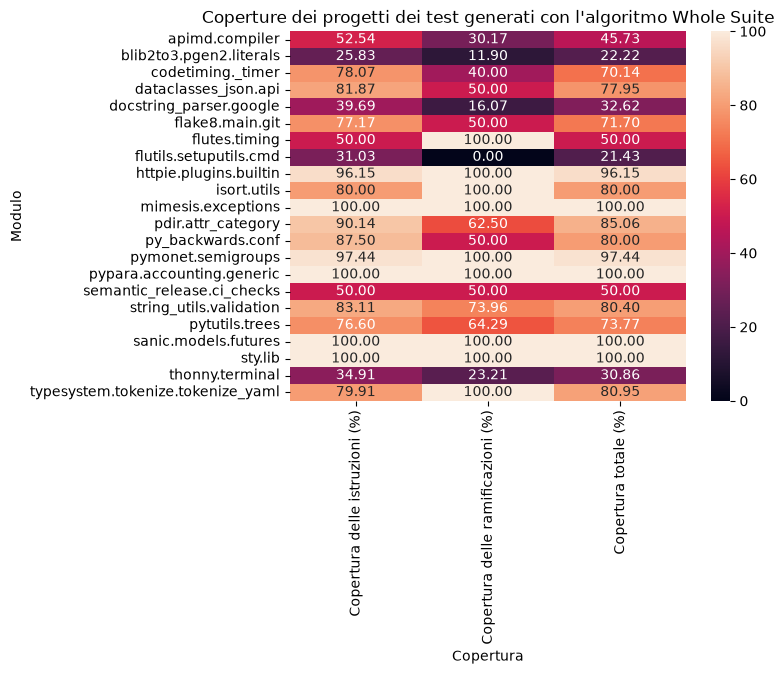

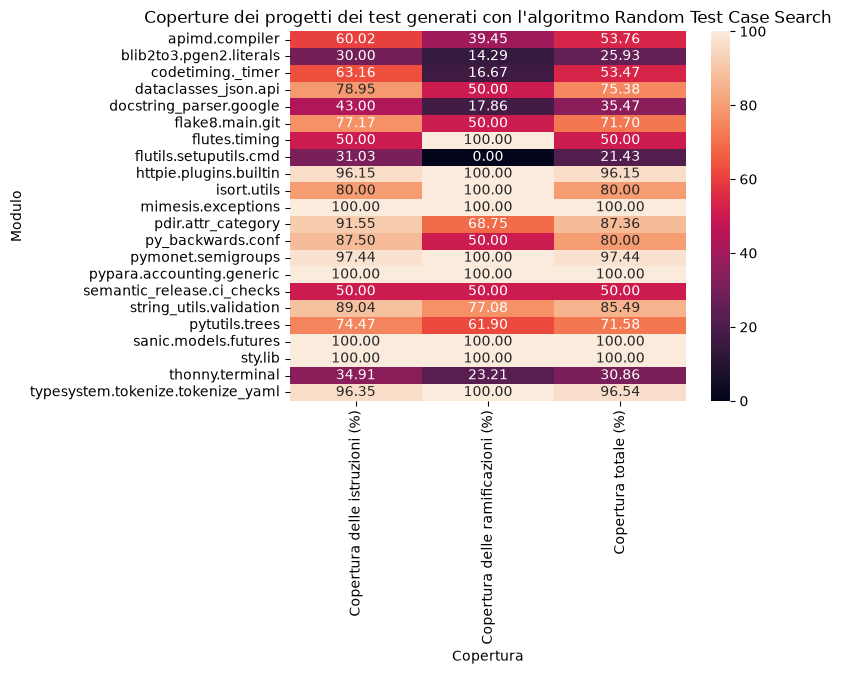

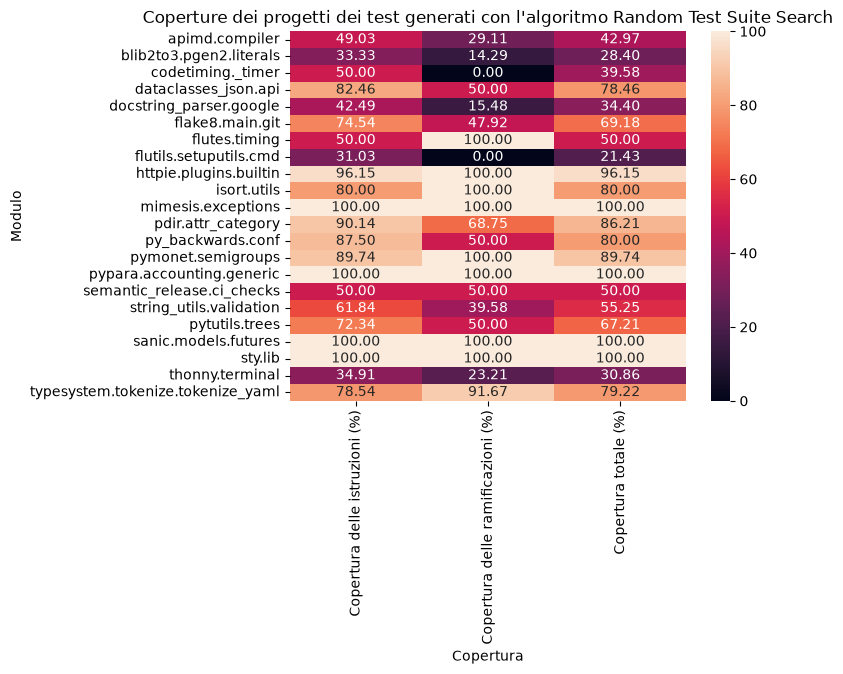

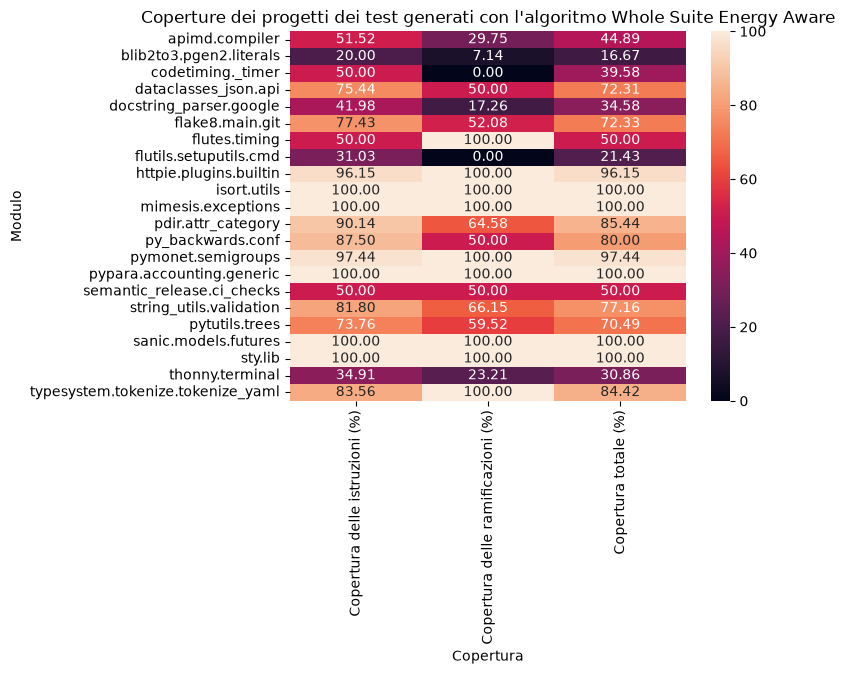

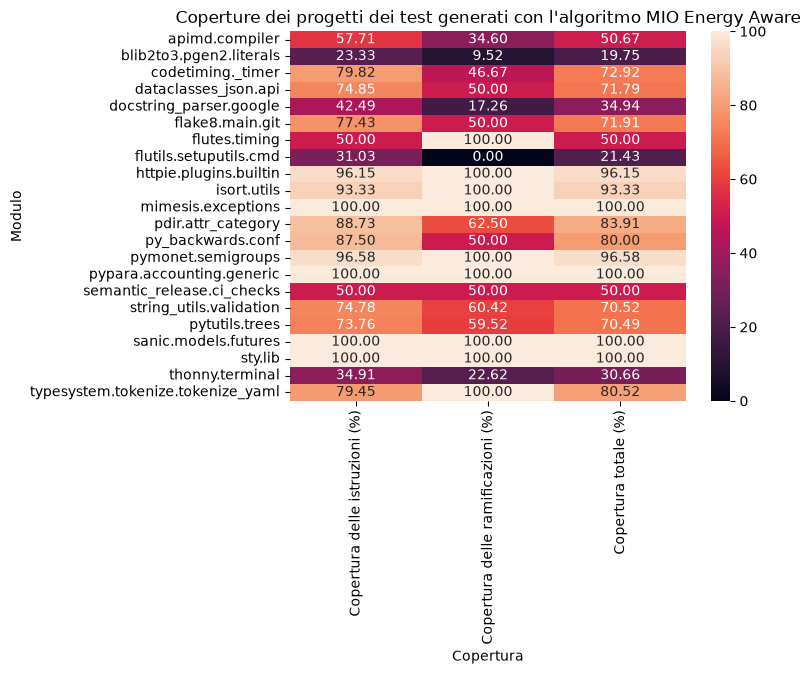

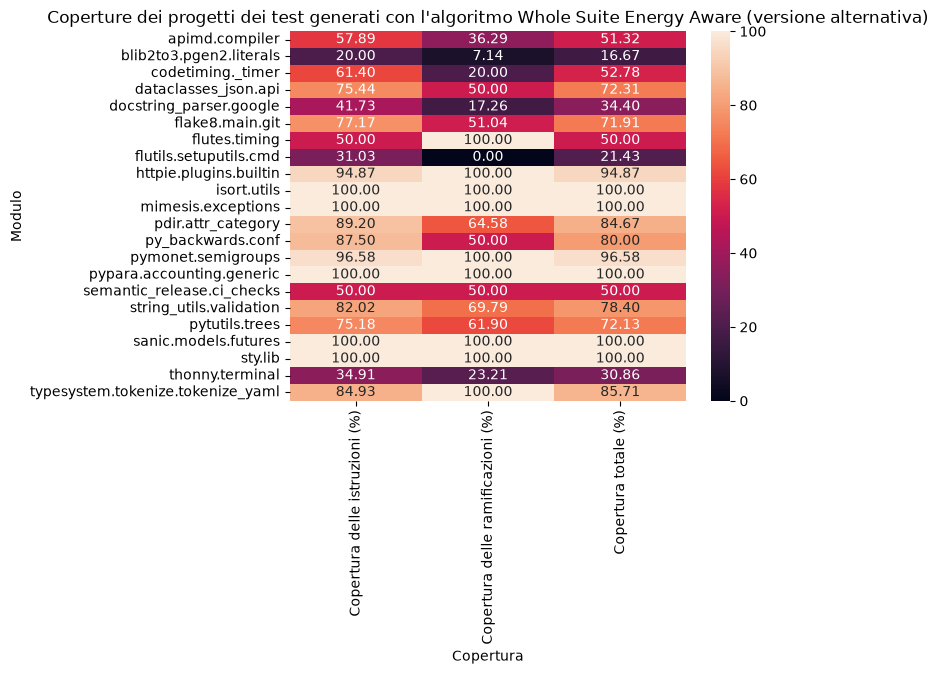

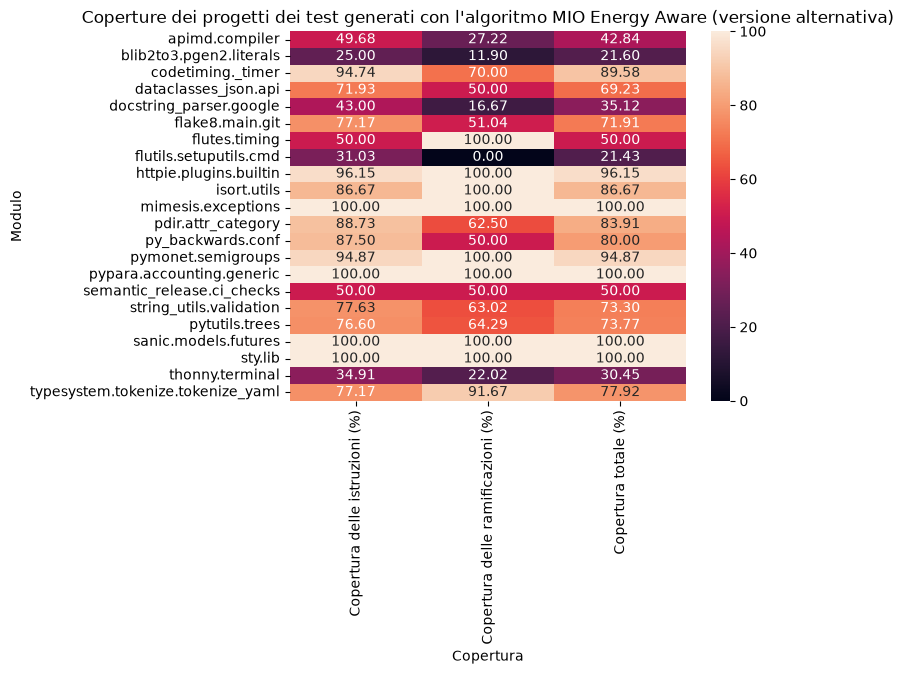

In [31]:
# Make a heatplot for the coverages of each project for that particular algorithm
def coverage_plot_of_projects(data, algorithm):
    df = data.loc[data['Algoritmo'] == algorithm, ['Copertura delle istruzioni (%)', 'Copertura delle ramificazioni (%)', 'Copertura totale (%)']]
    df.rename_axis(columns='Copertura', inplace=True)
    title = f"Coperture dei progetti dei test generati con l'algoritmo {pretty_algorithm(algorithm)}" 
    ax = sns.heatmap(df, annot=True, fmt='.2f')
    ax.set(title=title)
    return ax

plots = {}
# Make plots for coverages of each algorithm
for algorithm in ALGORITHMS:
    df = stats_summary.reset_index(['Algoritmo', 'Progetto'])
    try:
        plots[algorithm] = coverage_plot_of_projects(df, algorithm)
        plots[algorithm].get_figure().savefig(IMAGES_PATH / f'heat_coverage_{algorithm}.jpg', bbox_inches='tight')
        plt.show();
    except ValueError:
        # Ignore the value that is not an algorithm
        print(f'{algorithm} was skipped because it was not recognized as an algorithm.')
        continue
    

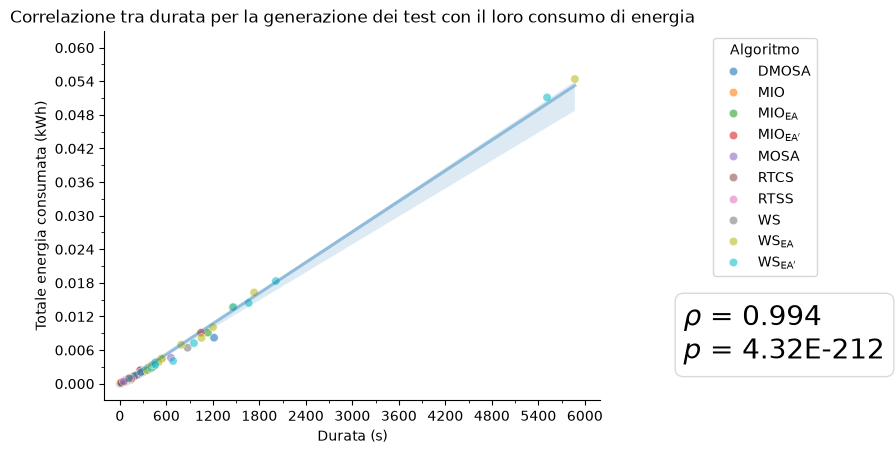

In [32]:
ax = plot_with_algorithms_and_regression(gen_summary,
                                         'Durata (s)',
                                         'Totale energia consumata (kWh)',
                                         (0,6000),
                                         (0,0.06),
                                         200,
                                         0.003,
                                         11,
                                         11,
                                         'Correlazione tra durata per la generazione dei test con il loro consumo di energia',
                                         pearson=False,
                                         linregression=True
                                        )
ax.xaxis.set_minor_locator(mpl.ticker.FixedLocator(range(300,6000,300)))
ax.get_figure().savefig(IMAGES_PATH / 'scatter_gen_time_energy.jpg', bbox_inches='tight')

In [33]:
# Correlation between total energy consumpion of both generation (with Pynguin) and execution (with Pytest)
# how=inner because it does not matter since the schema of the two tables is the same
gen_exec = fixed_gen.join(fixed_exec,
                          on=['Progetto', 'Algoritmo'],
                          how='inner',
                          lsuffix=' per la generazione dei test',
                          rsuffix=" per l'esecuzione dei test")
# fix the column names (move the unit of measurement at the end if it is in the column name)
column_names = {}
unit_of_measurement_regex = r'\s*\(.*\)\s*'
for col in gen_exec.columns:
    unit_of_measurement = re.findall(unit_of_measurement_regex, col)
    if unit_of_measurement != []:
        # there must be always one unit of measurement if it's in the column name
        fixed_unit_of_measurement = unit_of_measurement[0].strip()
        column_names[col] = ' '.join(col.split(unit_of_measurement[0], 1)) + f' {fixed_unit_of_measurement}'
gen_exec.rename(columns=column_names, inplace=True)

In [34]:
def gen_exec_plot(data, title=None, linregression=True, pearson=True):
    df = data.rename(columns={'Totale energia consumata per la generazione dei test (kWh)': 'Energia consumata per la generazione dei test (kWh)',
                              "Totale energia consumata per l'esecuzione dei test (kWh)" : "Energia consumata per l'esecuzione dei test (kWh)"})
    ax = plot_with_algorithms_and_regression(data=df,
                                             x="Energia consumata per l'esecuzione dei test (kWh)",
                                             y='Energia consumata per la generazione dei test (kWh)',
                                             xlim=(0,5e-5),
                                             ylim=(0,0.06),
                                             xspace=2.5e-6,
                                             yspace=0.003,
                                             xticks_num=11,
                                             yticks_num=11,
                                             title=title,
                                             linregression=linregression,
                                             pearson=pearson)
    xformatter = ax.yaxis.get_major_formatter()
    xformatter.set_useMathText(True)
    xformatter.set_powerlimits((-3,-2))
    yformatter = ax.xaxis.get_major_formatter()
    yformatter.set_useMathText(True)
    return ax

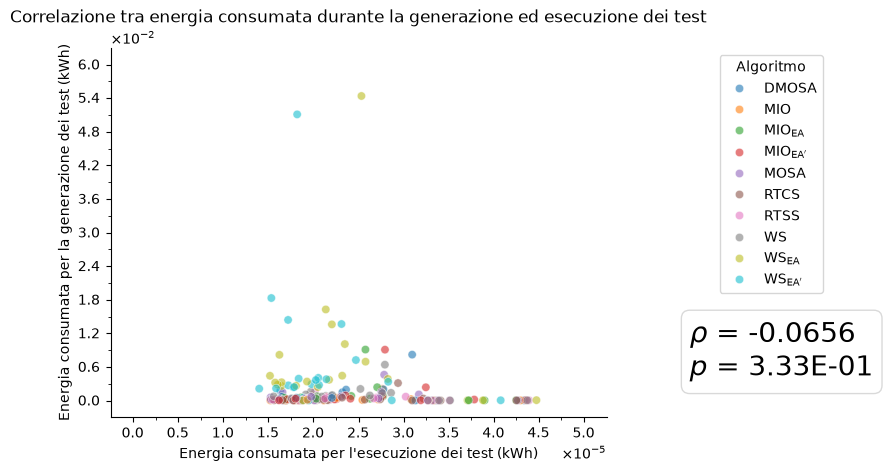

In [35]:
ax = gen_exec_plot(gen_exec,
                   title='Correlazione tra energia consumata durante la generazione ed esecuzione dei test',
                   linregression=False,
                   pearson=False)
ax.get_figure().savefig(IMAGES_PATH / 'scatter_gen_exec_energy.jpg', bbox_inches='tight')

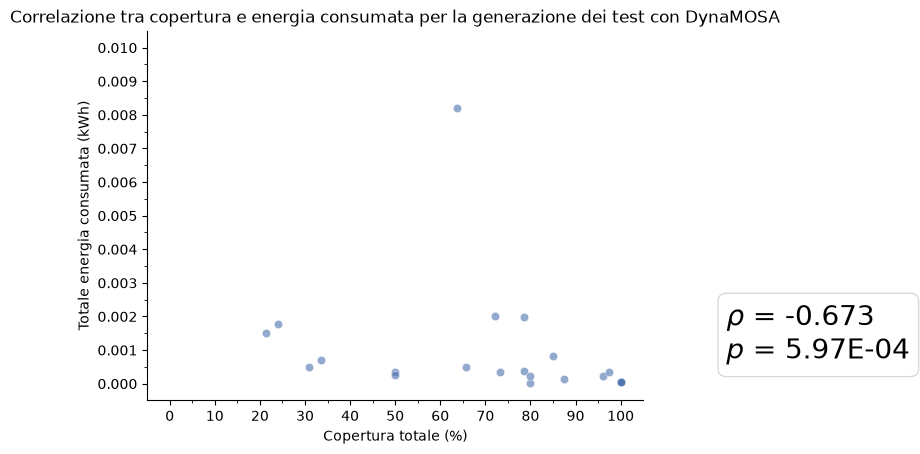

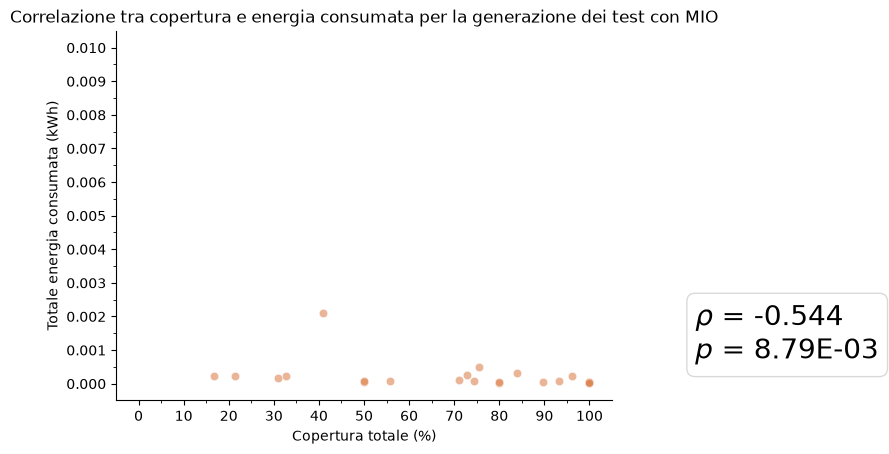

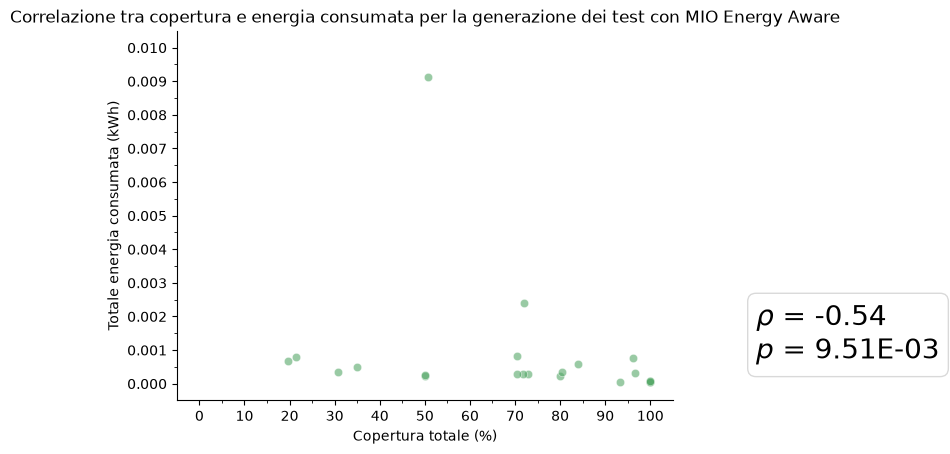

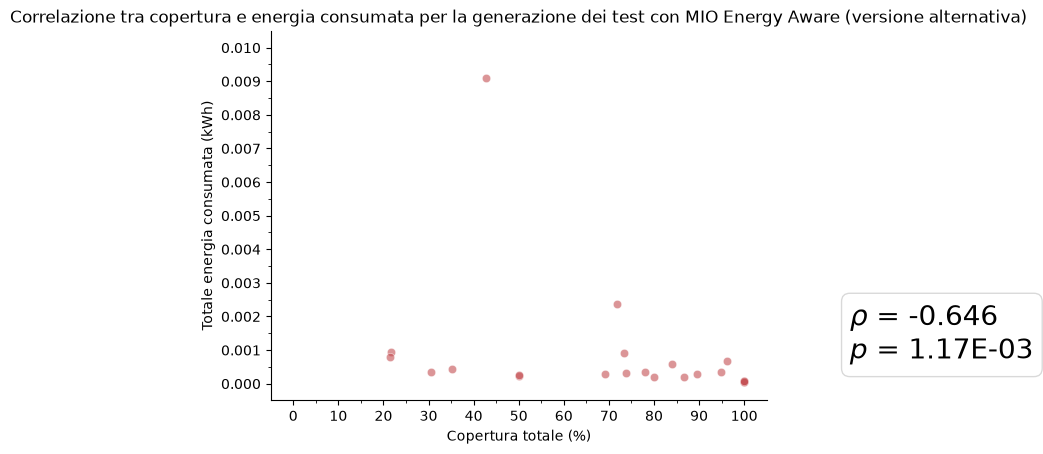

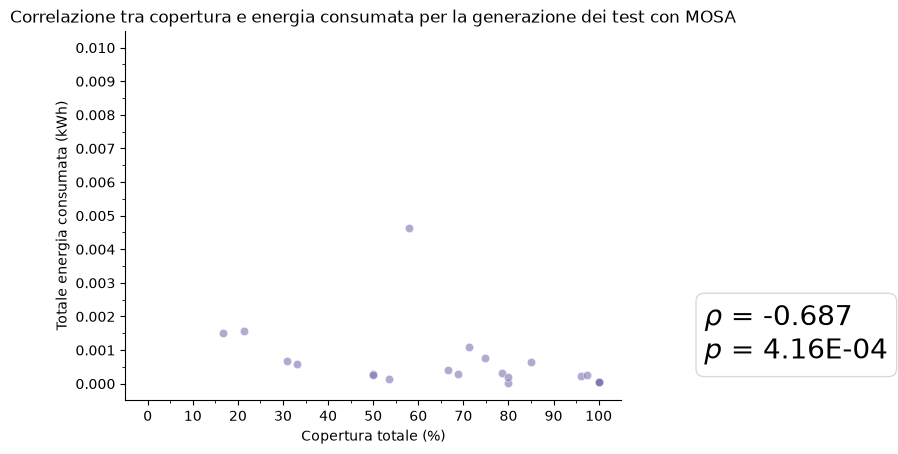

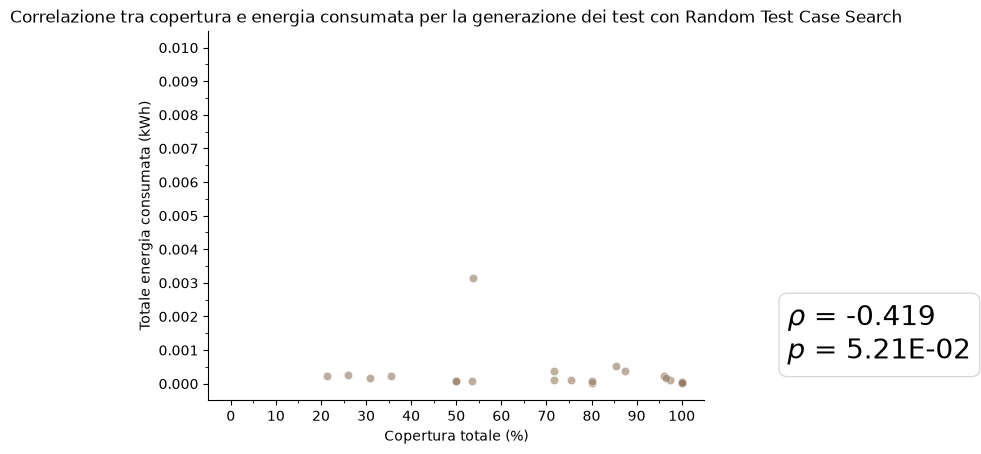

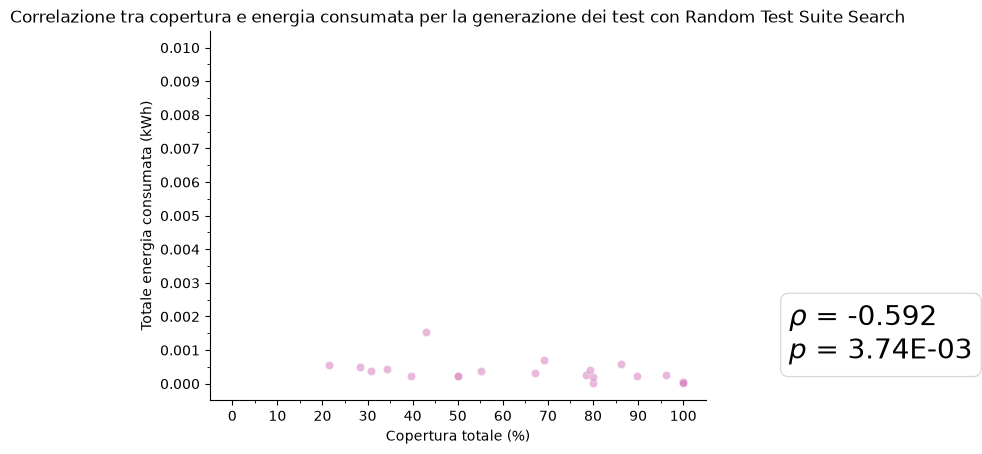

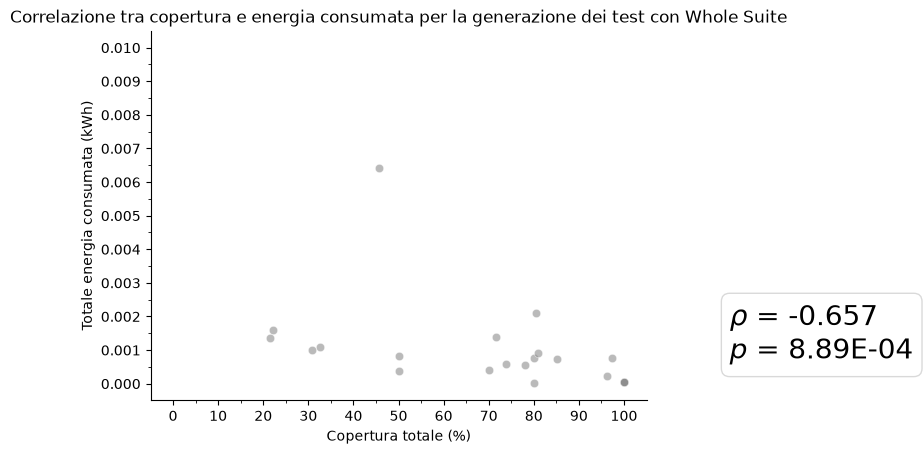

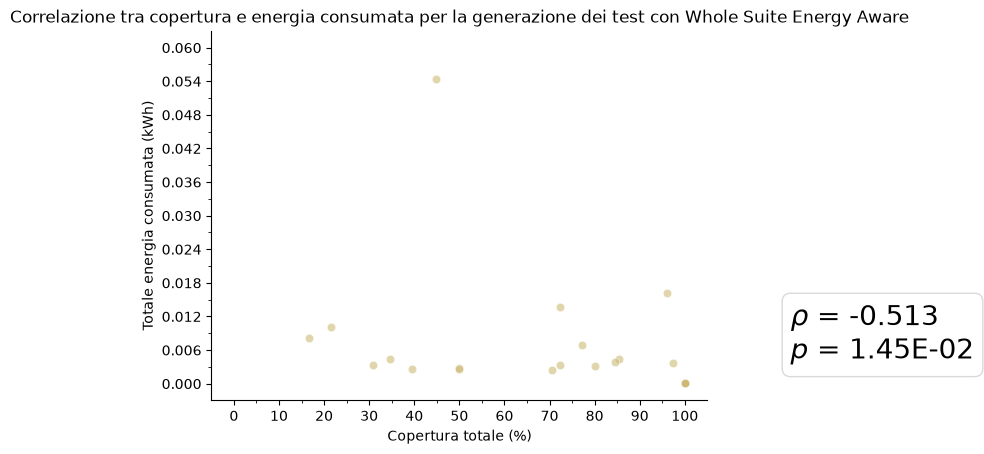

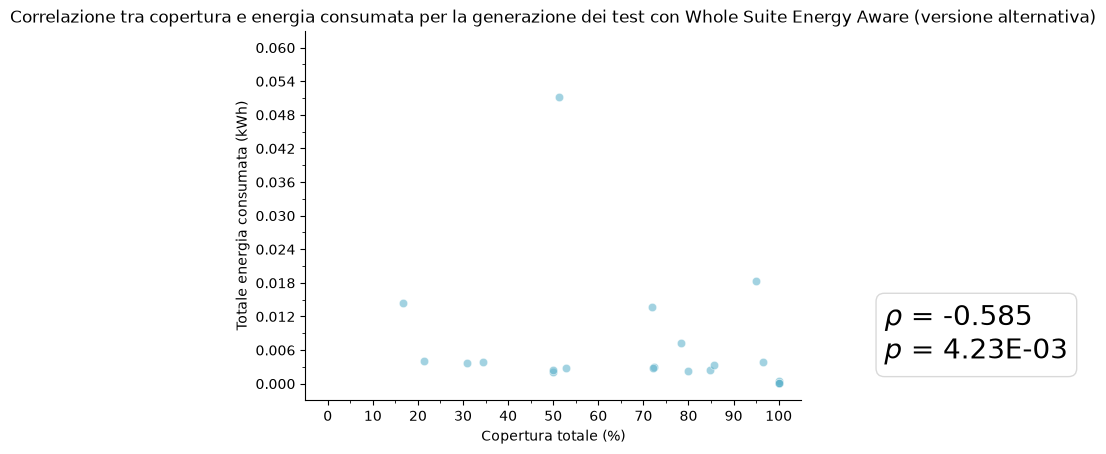

In [36]:
df = gen_summary.reset_index('Algoritmo')
col_pal = sns.color_palette('deep', len(ALGORITHMS))
for i, algorithm in enumerate(sorted(ALGORITHMS)):
    ax = plot_with_algorithms_and_regression(df[df['Algoritmo'] == algorithm],
                                             'Copertura totale (%)',
                                             'Totale energia consumata (kWh)',
                                             (0,100),
                                             (0,0.01) if algorithm != 'WHOLE_SUITE_ENERGY_AWARE' and
                                                         algorithm != 'WHOLE_SUITE_ENERGY_AWARE_ALT'
                                                      else (0,0.06),
                                             5,
                                             0.0005 if algorithm != 'WHOLE_SUITE_ENERGY_AWARE' and
                                                       algorithm != 'WHOLE_SUITE_ENERGY_AWARE_ALT'
                                                    else 0.003,
                                             11,
                                             11,
                                             f"Correlazione tra copertura e energia consumata per la generazione dei test con {pretty_algorithm(algorithm)}",
                                             linregression=False,
                                             pearson=False)
    ax.get_legend().remove()
    ax.collections[0].set_facecolor(col_pal[i])
    ax.get_figure().savefig(IMAGES_PATH / f'scatter_energy_cov_{algorithm}.jpg', bbox_inches='tight')
    plt.show();

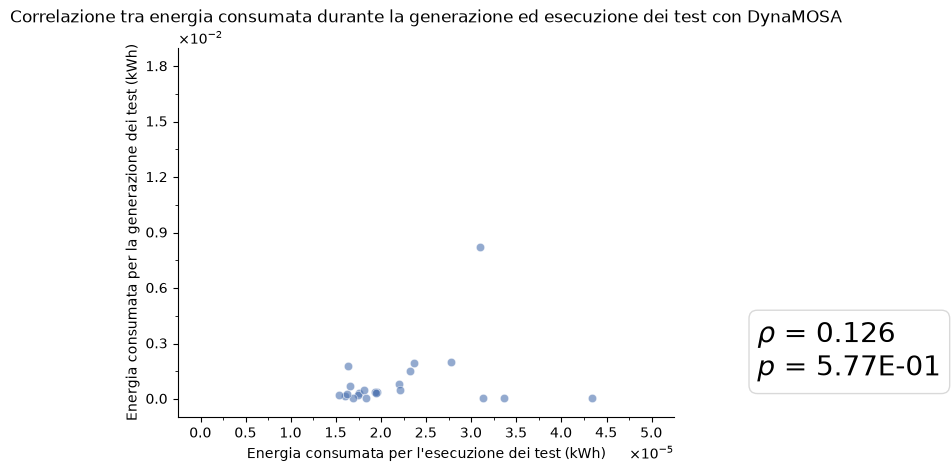

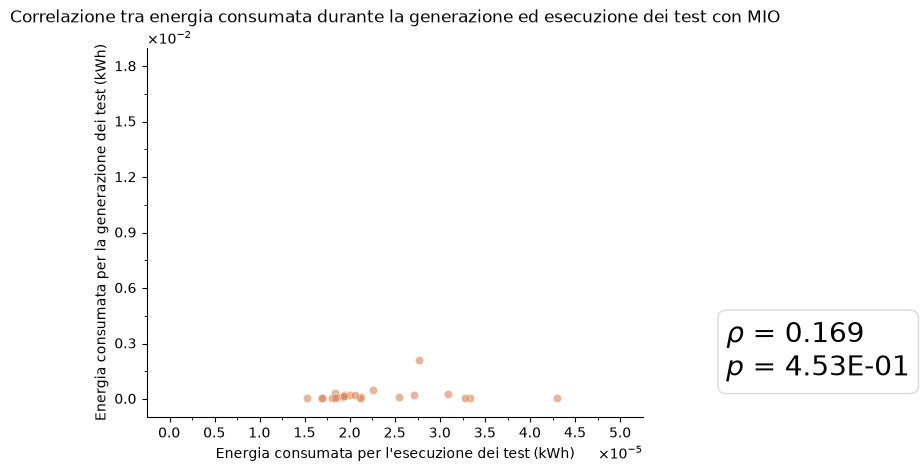

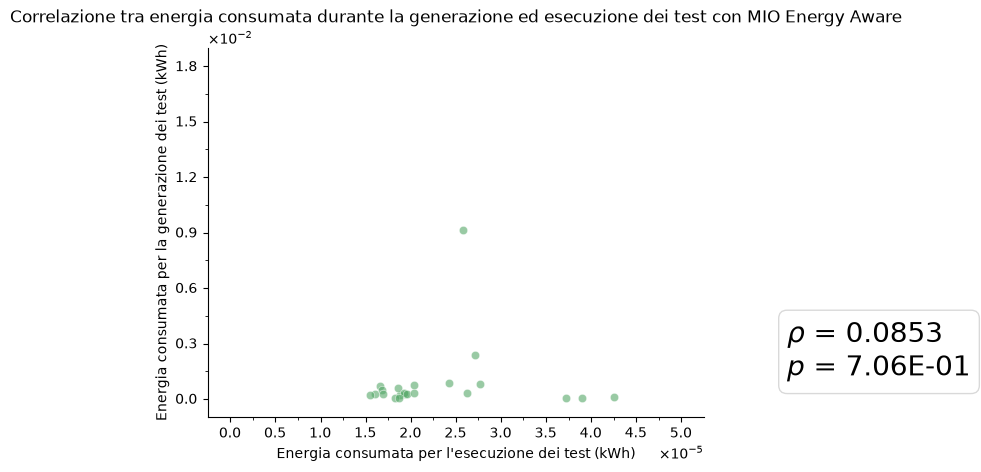

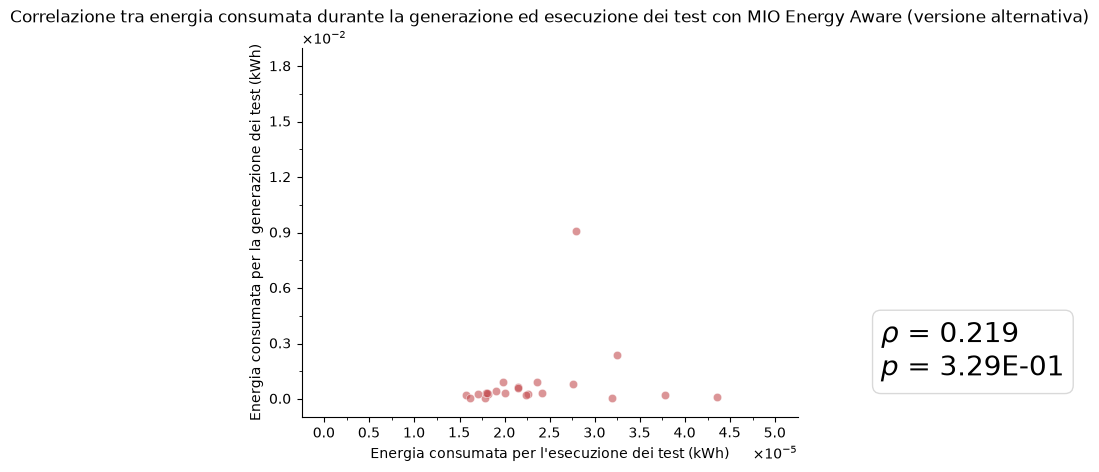

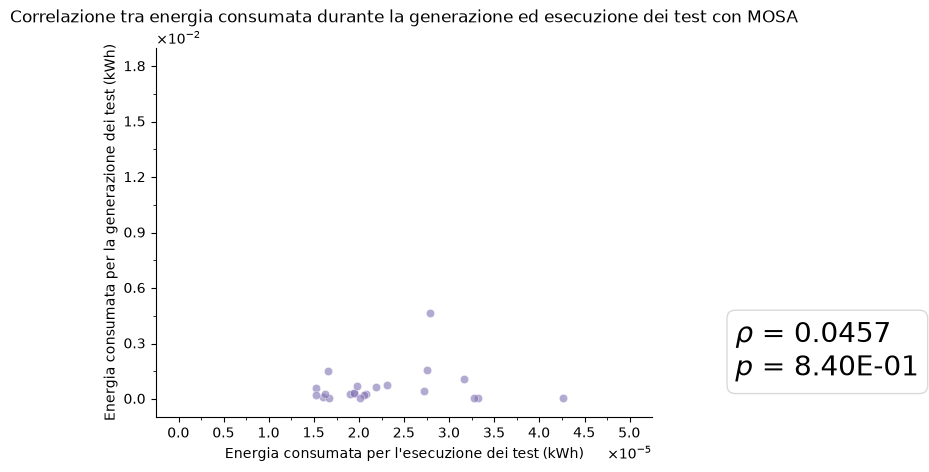

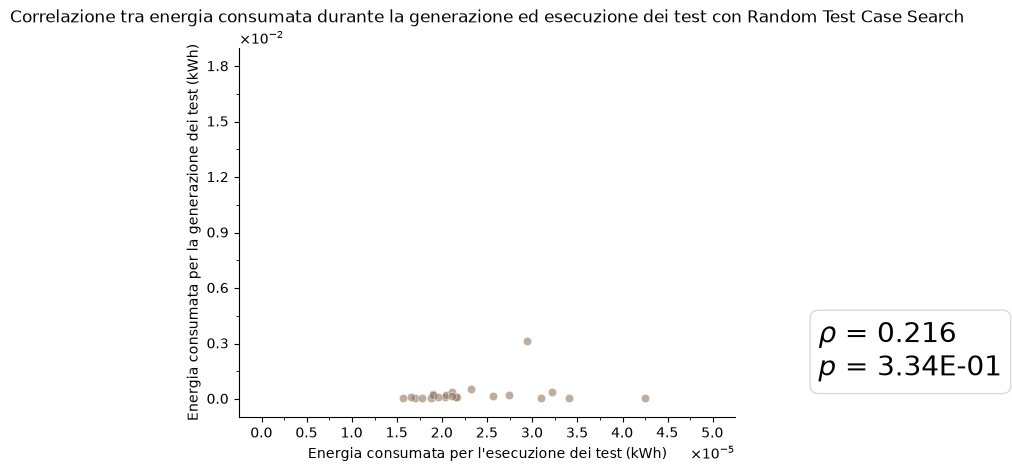

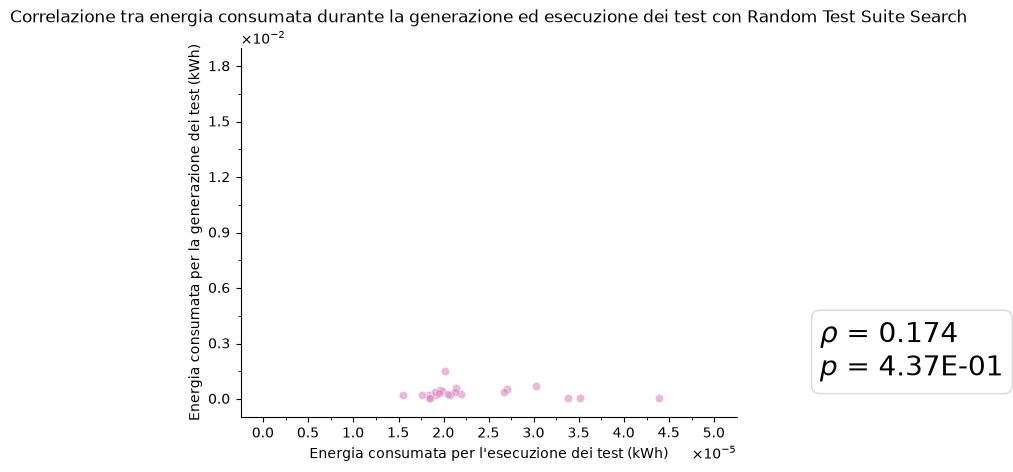

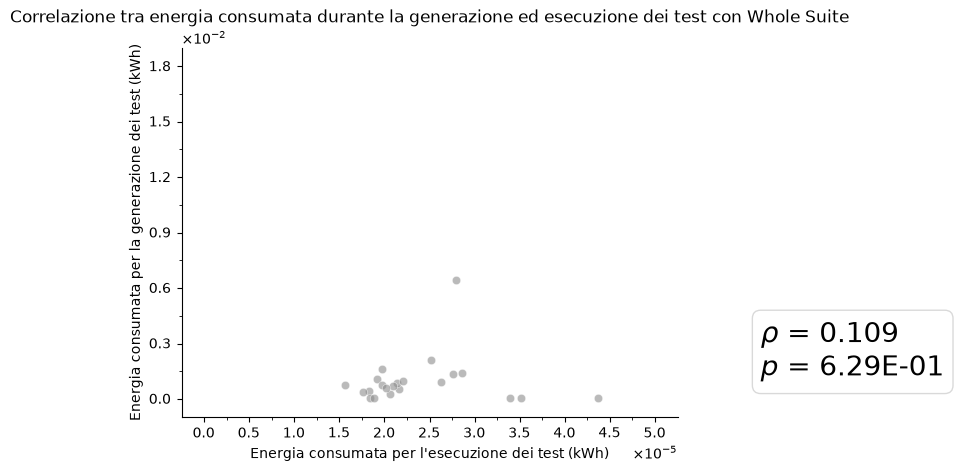

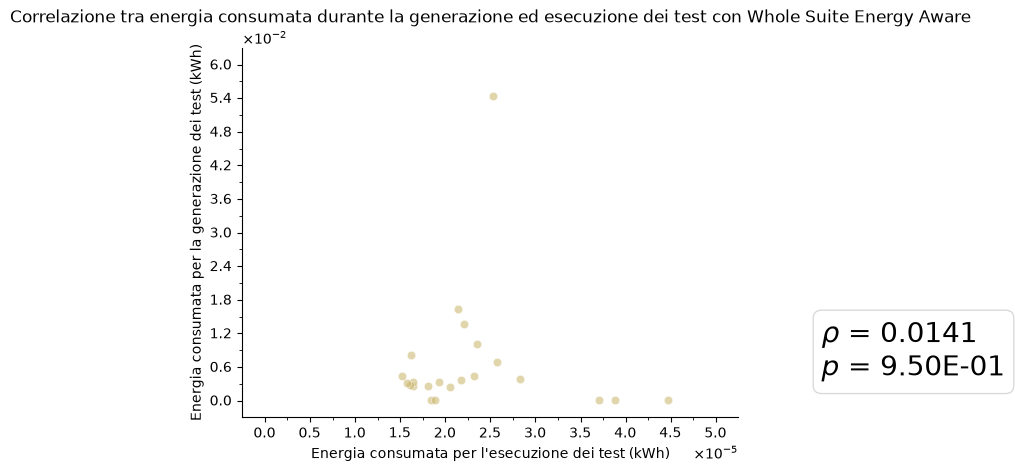

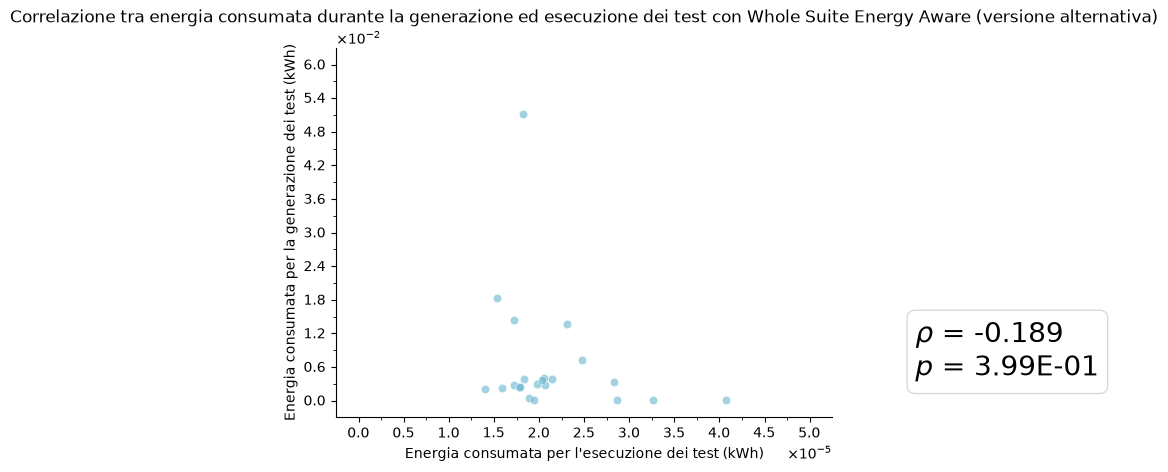

In [37]:
df = gen_summary.reset_index('Algoritmo')
col_pal = sns.color_palette('deep', len(ALGORITHMS))
df = gen_exec.reset_index('Algoritmo')
for i, algorithm in enumerate(sorted(ALGORITHMS)):
    ax = gen_exec_plot(df[df['Algoritmo'] == algorithm],
                       title=f"Correlazione tra energia consumata durante la generazione ed esecuzione dei test con {pretty_algorithm(algorithm)}",
                       linregression=False,
                       pearson=False)
    ax.get_legend().remove()
    ax.collections[0].set_facecolor(col_pal[i])
    if algorithm != 'WHOLE_SUITE_ENERGY_AWARE' and algorithm != 'WHOLE_SUITE_ENERGY_AWARE_ALT':
        ax.set_ylim(ymin=-0.001,ymax=0.019)
        ax.yaxis.set_major_locator(mpl.ticker.FixedLocator(np.arange(0,1.81e-2,0.3e-2)))
        ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(0,1.81e-2,0.15e-2)))
    ax.get_figure().savefig(IMAGES_PATH / f'scatter_gen_exec_energy_{algorithm}.jpg', bbox_inches='tight')
    plt.show();

In [38]:
'''To be interpreted as:
    - if coverage(module) < 0 then alg1 has less coverage than alg2 for that module
    - if coverage(module) > 0 then alg1 has more coverage than alg1 for that module
    - if coverage(module) == 0 then alg1 and alg2 have the same coverage for that module
'''
def difference_in_coverage(alg1, alg2):
    if alg1 not in ALGORITHMS or alg2 not in ALGORITHMS:
        raise ValueError('One or both arguments are not recognized as algorithms.')
    df = stats_summary.reset_index(['Progetto', 'Algoritmo']).rename_axis(columns='Copertura')
    df1 = df.loc[df['Algoritmo'] == alg1, ['Copertura totale (%)', 'Copertura delle istruzioni (%)', 'Copertura delle ramificazioni (%)']]
    df2 = df.loc[df['Algoritmo'] == alg2, ['Copertura totale (%)', 'Copertura delle istruzioni (%)', 'Copertura delle ramificazioni (%)']]
    return df1 - df2

In [39]:
def coverage_difference_table(alg1, alg2):
    diff_algs = difference_in_coverage(alg1,alg2)
    diff_cols = diff_algs.map(lambda x: 'orangered' if x < 0 else 'lawngreen' if x > 0 else 'lightgray')
    # for some reason you can't create a table without a graph, so we have to hide the empty graph
    fig, ax = plt.subplots()
    fig.patch.set_visible(False)
    ax.axis('off')
    ax.axis('tight')
    tab = ax.table(cellText=diff_algs.map('{:.2f}'.format),
                   cellColours=diff_cols.values,
                   loc='center'
                  )
    tab.scale(2,2)
    ax.set_title(f'Copertura({pretty_algorithm(alg1)}) - Copertura({pretty_algorithm(alg2)})', y=1.5, pad=20)
    return ax

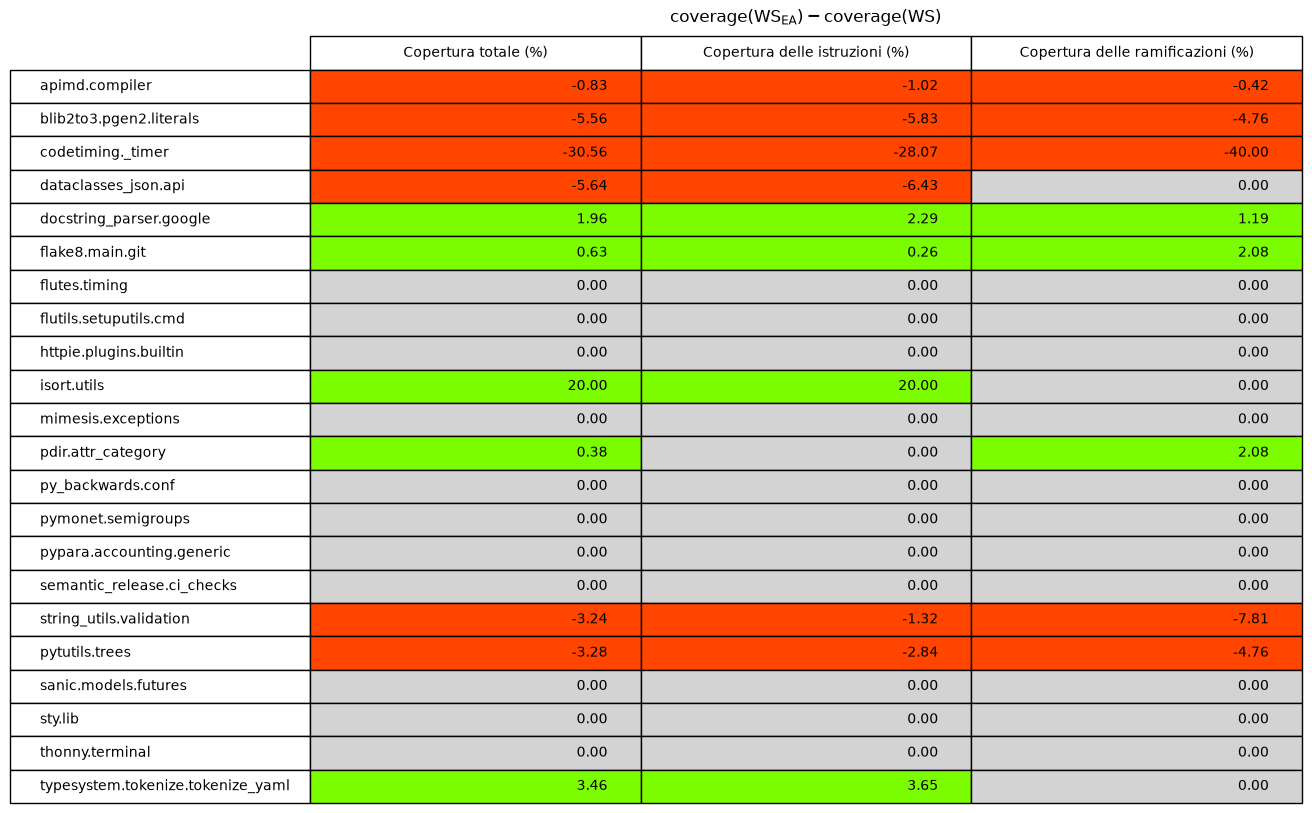

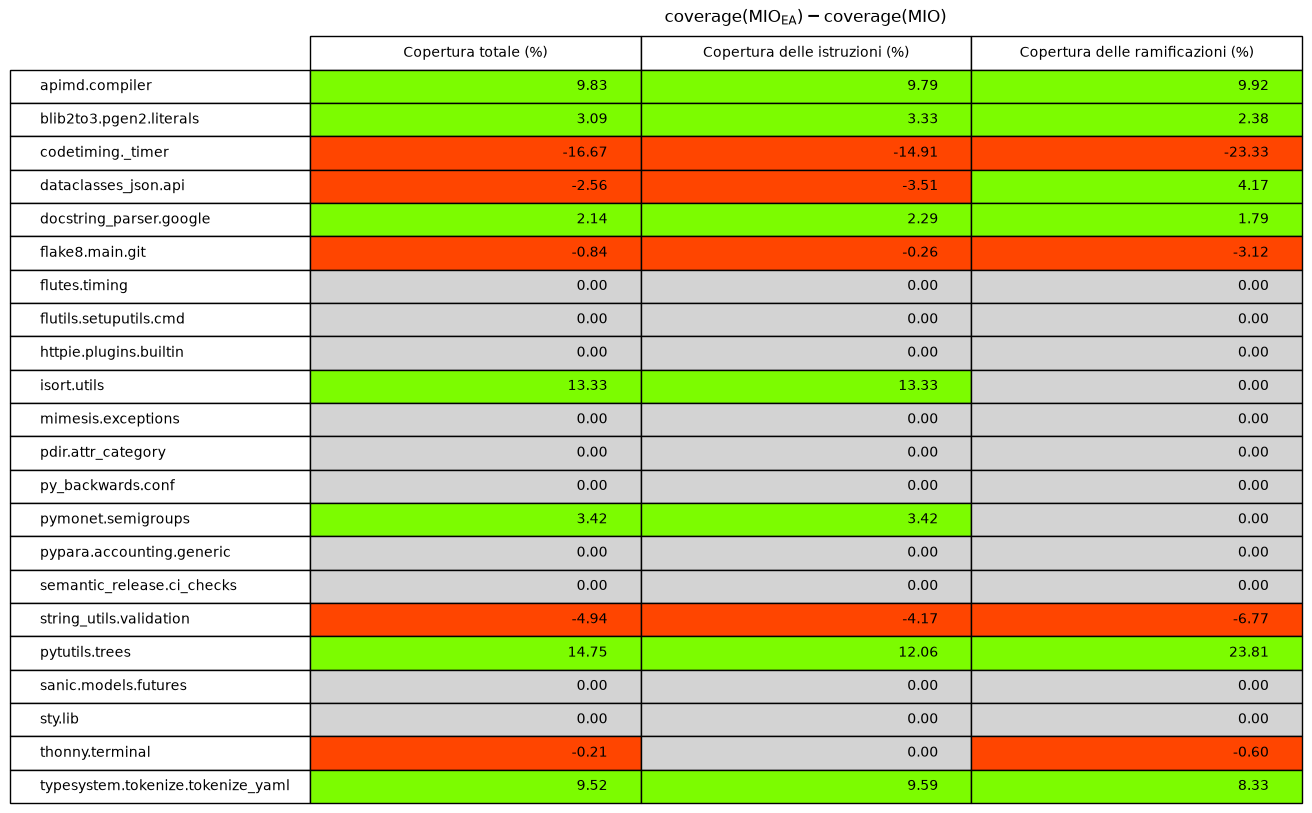

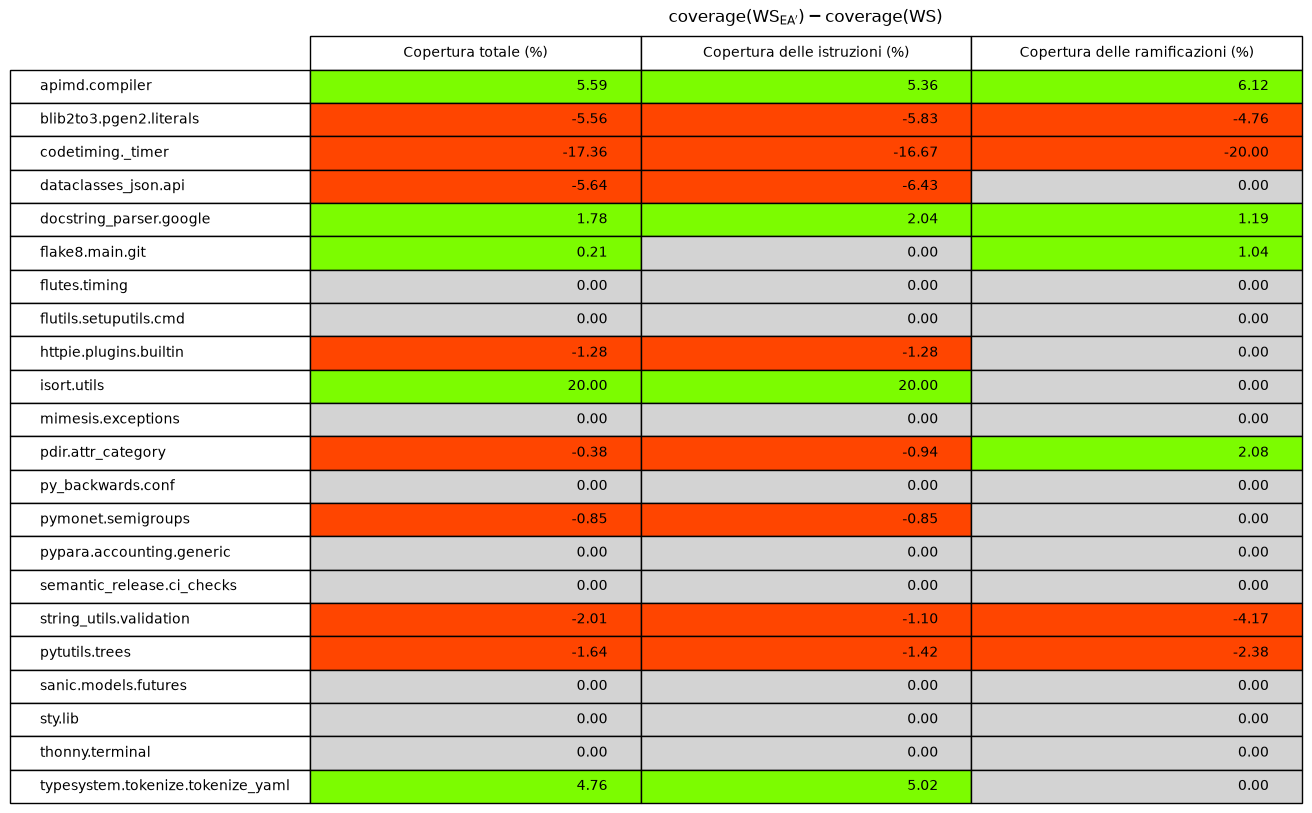

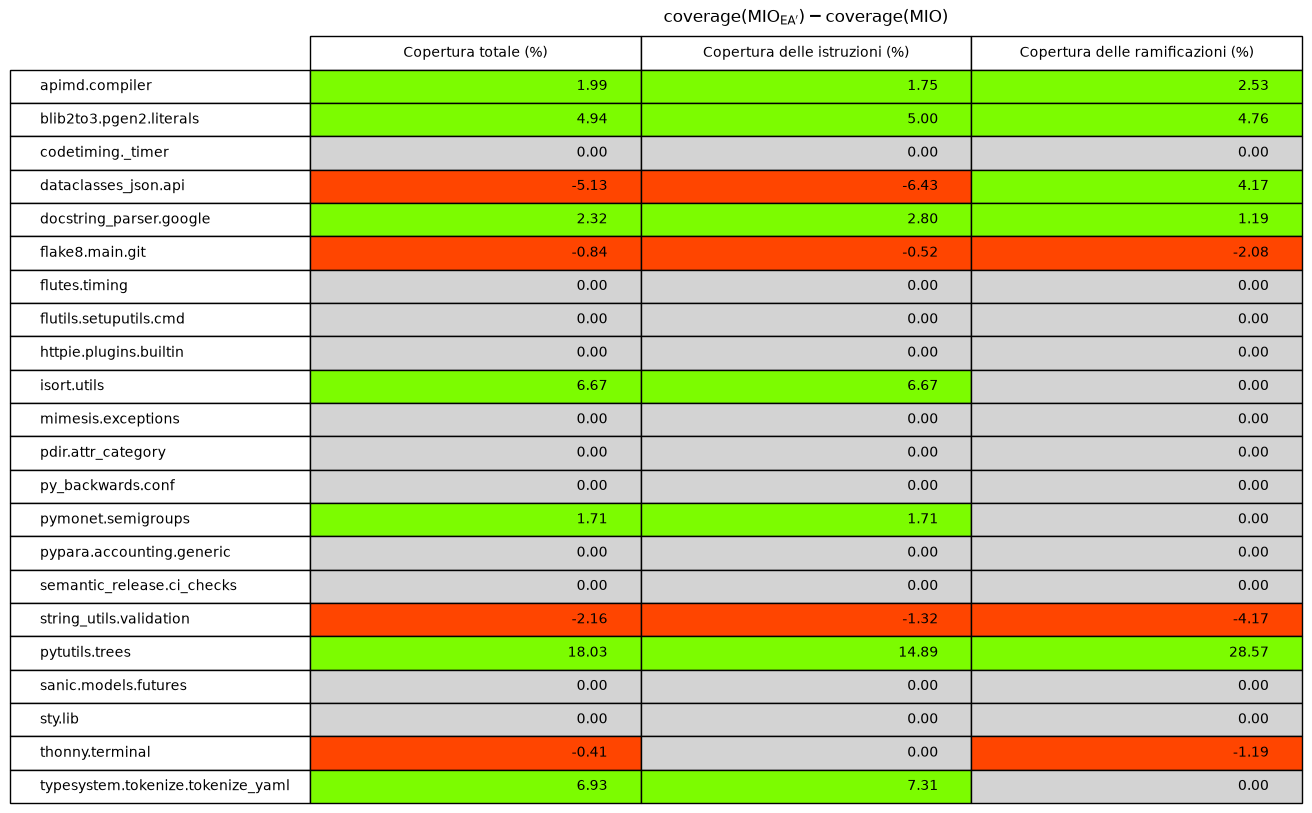

In [40]:
ax = coverage_difference_table('WHOLE_SUITE_ENERGY_AWARE', 'WHOLE_SUITE')
ax.set_title(r'$\text{coverage}(\text{WS}_\text{EA}) - \text{coverage(WS)}$', y=1.5, pad=20)
ax.get_figure().savefig(IMAGES_PATH / f'table_WSEA_WS.jpg', bbox_inches='tight')
plt.show();
ax = coverage_difference_table('MIO_ENERGY_AWARE', 'MIO')
ax.set_title(r'$\text{coverage}(\text{MIO}_\text{EA}) - \text{coverage(MIO)}$', y=1.5, pad=20)
ax.get_figure().savefig(IMAGES_PATH / f'table_MIOEA_MIO.jpg', bbox_inches='tight')
ax = coverage_difference_table('WHOLE_SUITE_ENERGY_AWARE_ALT', 'WHOLE_SUITE')
ax.set_title(r"$\text{coverage}(\text{WS}_{\text{EA}'}) - \text{coverage(WS)}$", y=1.5, pad=20)
ax.get_figure().savefig(IMAGES_PATH / f'table_WSEAALT_WS.jpg', bbox_inches='tight')
plt.show();
ax = coverage_difference_table('MIO_ENERGY_AWARE_ALT', 'MIO')
ax.set_title(r"$\text{coverage}(\text{MIO}_{\text{EA}'}) - \text{coverage(MIO)}$", y=1.5, pad=20)
ax.get_figure().savefig(IMAGES_PATH / f'table_MIOEAALT_MIO.jpg', bbox_inches='tight')

# Research Questions (RQs):
## RQ1. Per la generazione dei test, quali algoritmi hanno rispettivamente consumato più energia e meno energia, e quali sono stati i moduli più costosi e meno costosi in assoluto dal punto di vista energetico? I risultati sono analoghi anche dal punto di vista della durata di generazione dei test?
## RQ2. Esistono differenze sostanziali di energia consumata per l'esecuzione dei test generati con i diversi algoritmi? Quali sono i moduli che hanno avuto i test più costosi e meno costosi dal punto di vista energetico? I risultati sono analoghi anche dal punto di vista della durata di esecuzione dei test?
## RQ3. Quali sono gli algoritmi che hanno generato test migliori? Ovvero, quali sono gli algoritmi che hanno avuto la copertura più alta, sia dal punto di vista delle istruzioni, delle ramificazioni e in totale (cioè considerando sia le istruzioni che le ramificazioni coperte)? Confrontando i tipi diversi di copertura analizzati, i risultati differiscono considerevolmente oppure risultano simili tra loro?
## RQ4. L'energia consumata per la generazione dei test è correlata con la copertura di essi? In particolare, esiste una correlazione lineare? Se sì, quanto risulta forte? Esistono risultati simili anche tra l'energia consumata per l'esecuzione dei test e la loro copertura? I due tipi di energia sono correlati?
## RQ5. Esiste una correlazione lineare tra l'energia consumata durante la generazione dei test e la durata per generarli? Se sì, quanto risulta forte? Quale potrebbe essere il motivo del risultato?

# NEW Research Questions (RQs):

## **RQ1[Consumo generazione dei test]** Qual è il consumo energetico per la generazione dei test al variare dell'algoritmo?

## **RQ2[Consumo esecuzione dei test]** Qual è il consumo energetico per l'esecuzione dei test al variare dell'algoritmo? Esiste una correlazione con il consumo energetico per la generazione dei test?

## **RQ3[Copertura dei test]** Qual è la copertura raggiunta dai test generati al variare dell'algoritmo? Esiste una correlazione con il consumo energetico per la generazione dei test?

In [41]:
# Statistical tests on the total energy consumption of the execution of tests with Whole Suite and Whole Suite Energy Aware
def get_samples_of(data, column, alg1, alg2):
    if column not in data.columns:
        raise ValueError(f"Column '{column}' was not found in the given data frame.")
    if alg1 not in ALGORITHMS:
        raise ValueError('One of the given algorithms was not recognized.')
    x = data.filter(regex=fr'\b{alg1}\b', axis=0)[column]
    y = data.filter(regex=fr'\b{alg2}\b', axis=0)[column]
    return x, y

def vargha_delaney(x, y):
    more = 0
    same = 0
    for i in x:
        for j in y:
            if i == j:
                same += 1
            elif i > j:
                more += 1
    return (more + 0.5*same) / (len(x) * len(y))

def get_mannwhitneyu_results(x, y):
    ux, p = st.mannwhitneyu(x,y)
    a12_x = vargha_delaney(x,y)
    uy = x.shape[0]*y.shape[0]-ux
    a12_y = 1 - a12_x
    return {'Ux': ux,
            'A12_x': a12_x,
            'Uy': uy,
            'A12_y': a12_y,
            'p': p,
           }

In [42]:
# Gets the two samples of the total energy consumed during execution of tests generated with both WS and WSEA
x, y = get_samples_of(fixed_exec, 'Totale energia consumata (kWh)', 'WHOLE_SUITE', 'WHOLE_SUITE_ENERGY_AWARE')

In [43]:
# Assumes that x and y are independent!
results = get_mannwhitneyu_results(x.reset_index('Algoritmo', drop=True, inplace=False), y.reset_index('Algoritmo', drop=True, inplace=False))
print(f'{pretty_algorithm('WHOLE_SUITE')} vs {pretty_algorithm('WHOLE_SUITE_ENERGY_AWARE')}:')
for res in results:
    print(f'{res} = {results[res]}')

x, y = get_samples_of(fixed_exec, 'Totale energia consumata (kWh)', 'MIO', 'MIO_ENERGY_AWARE')
print(f'{pretty_algorithm('MIO')} vs {pretty_algorithm('MIO_ENERGY_AWARE')}:')
results = get_mannwhitneyu_results(x.reset_index('Algoritmo', drop=True, inplace=False), y.reset_index('Algoritmo', drop=True, inplace=False))
for res in results:
    print(f'{res} = {results[res]}')

Whole Suite vs Whole Suite Energy Aware:
Ux = 275.0
A12_x = 0.5681818181818182
Uy = 209.0
A12_y = 0.43181818181818177
p = 0.4455466812579779
MIO vs MIO Energy Aware:
Ux = 261.0
A12_x = 0.5392561983471075
Uy = 223.0
A12_y = 0.4607438016528925
p = 0.6641115642981482


In [44]:
# assumes it uses the wilcox zero method (default)
def get_wilcoxon_results(x, y):
    t, p = st.wilcoxon(x,y)
    r = get_wilcoxon_effect_size(x,y)
    return {'T': t,
            'r': r,
            'p': p
           }

# assumes it uses the wilcox zero method (default)
def get_wilcoxon_effect_size(x, y):
    diff = x.reset_index(drop=True) - y.reset_index(drop=True)
    # since we assume that the statistic was calculated with the wilcox zero method, we remove the differences equal to zero
    diff = diff[diff != 0]
    # Scipy knows best
    ranks = st.rankdata(diff.abs())
    # r = (Rp - Rn)/(Rp + Rn) == W/S
    rp = ranks[diff > 0].sum()
    rn = ranks[diff < 0].sum()
    r = (rp - rn)/(rp + rn)
    # NB: we are basically calculating T by hand, we could just do T = min(Rp,Rn) and that's it, but Scipy knows best
    return r

def calculate_wilcoxon(data, column, alg1, alg2):
    x, y = get_samples_of(data, column, alg1, alg2)
    res = get_wilcoxon_results(x, y)
    for r in res:
        print(f'{r}: {res[r]}')
    return res

In [45]:
# What if they are not independent? Use Wilcoxon
print(f'{pretty_algorithm('WHOLE_SUITE')} vs {pretty_algorithm('WHOLE_SUITE_ENERGY_AWARE')}:')
results1 = calculate_wilcoxon(fixed_exec, 'Totale energia consumata (kWh)', 'WHOLE_SUITE', 'WHOLE_SUITE_ENERGY_AWARE')
print(f'{pretty_algorithm('MIO')} vs {pretty_algorithm('MIO_ENERGY_AWARE')}:')
results2 = calculate_wilcoxon(fixed_exec, 'Totale energia consumata (kWh)', 'MIO', 'MIO_ENERGY_AWARE')
print(f'{pretty_algorithm('WHOLE_SUITE')} vs {pretty_algorithm('WHOLE_SUITE_ENERGY_AWARE_ALT')}:')
results1 = calculate_wilcoxon(fixed_exec, 'Totale energia consumata (kWh)', 'WHOLE_SUITE', 'WHOLE_SUITE_ENERGY_AWARE_ALT')
print(f'{pretty_algorithm('MIO')} vs {pretty_algorithm('MIO_ENERGY_AWARE_ALT')}:')
results2 = calculate_wilcoxon(fixed_exec, 'Totale energia consumata (kWh)', 'MIO', 'MIO_ENERGY_AWARE_ALT')

Whole Suite vs Whole Suite Energy Aware:
T: 101.0
r: 0.2015810276679842
p: 0.42448854446411133
MIO vs MIO Energy Aware:
T: 123.0
r: 0.02766798418972332
p: 0.9239659309387207
Whole Suite vs Whole Suite Energy Aware (versione alternativa):
T: 55.0
r: 0.5652173913043478
p: 0.018956661224365234
MIO vs MIO Energy Aware (versione alternativa):
T: 84.0
r: -0.3359683794466403
p: 0.1761918067932129


# Cosa si è imparato
In ogni caso, che sia che l'energia consumata durante l'esecuzione dei test con *Whole Suite* e l'energia consumata durante l'esecuzione con *Whole Suite Energy Aware* siano variabili indipendenti tra loro ~~(anche se probabilmente no)~~, essendo il p-value un valore più alto del 5%, **fallisce la refutazione dell'ipotesi nulla** (che dice che non ci sono differenze di energia tra i due tipi di test) e quindi **non possiamo dire che eseguire i test generati con questi due algoritmi porti a differenze di efficienza**. Il caso analogo vale anche per *MIO* e *MIO Energy Aware* e *MIO* e *MIO Energy Aware (versione alternativa)*. Sorprendentemente però la differenza tra *Whole Suite* e *Whole Suite Energy Aware (versione alternativa)* è significativa: **si rifiuta l'ipotesi nulla** e si accetta quella alternativa: **la differenza della mediana dell'energia consumata durante l'esecuzione tra *Whole Suite* e *Whole Suite Energy Aware (versione alternativa)* è diversa da zero**. In particolare con un valore di r=0.565 si ha un grande effetto positivo, cioè che le energie durante l'esecuzione dei test generati con i due algoritmi sono ben distinte, con valori di energia sistematicamente più alti per *Whole Suite* senza la metrica di ottimizzazione dell'energia rispetto allo stesso algoritmo con la metrica alternativa di energia.

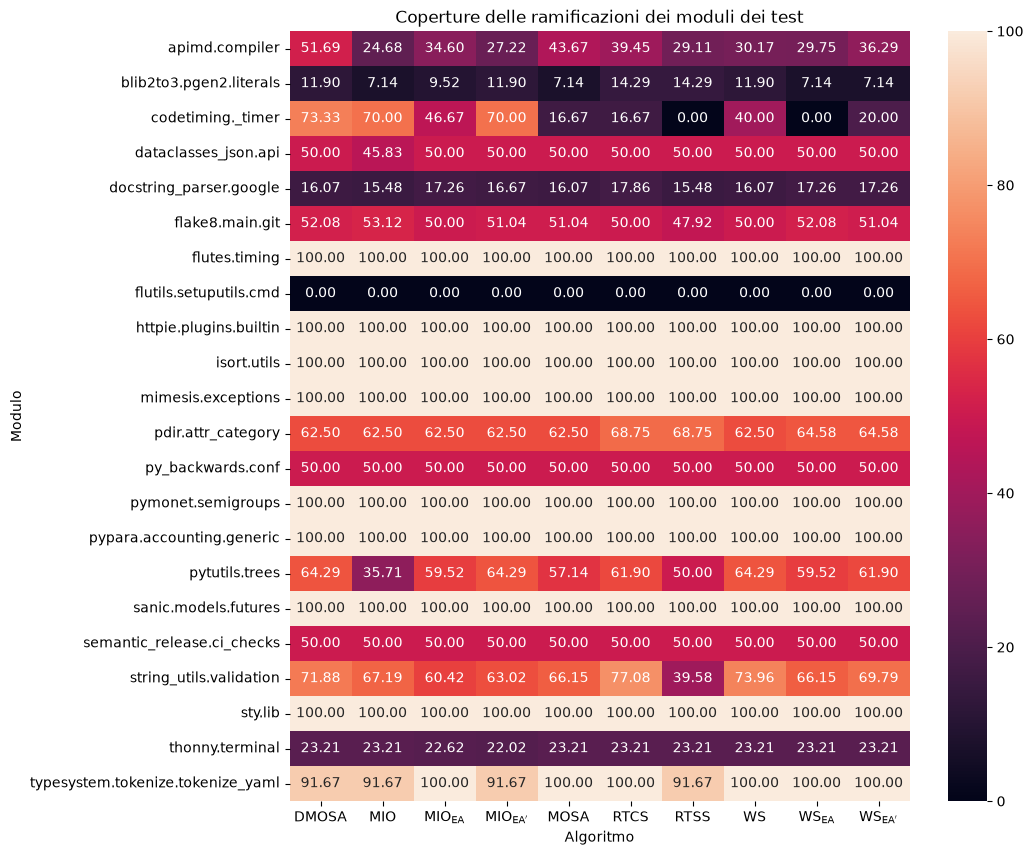

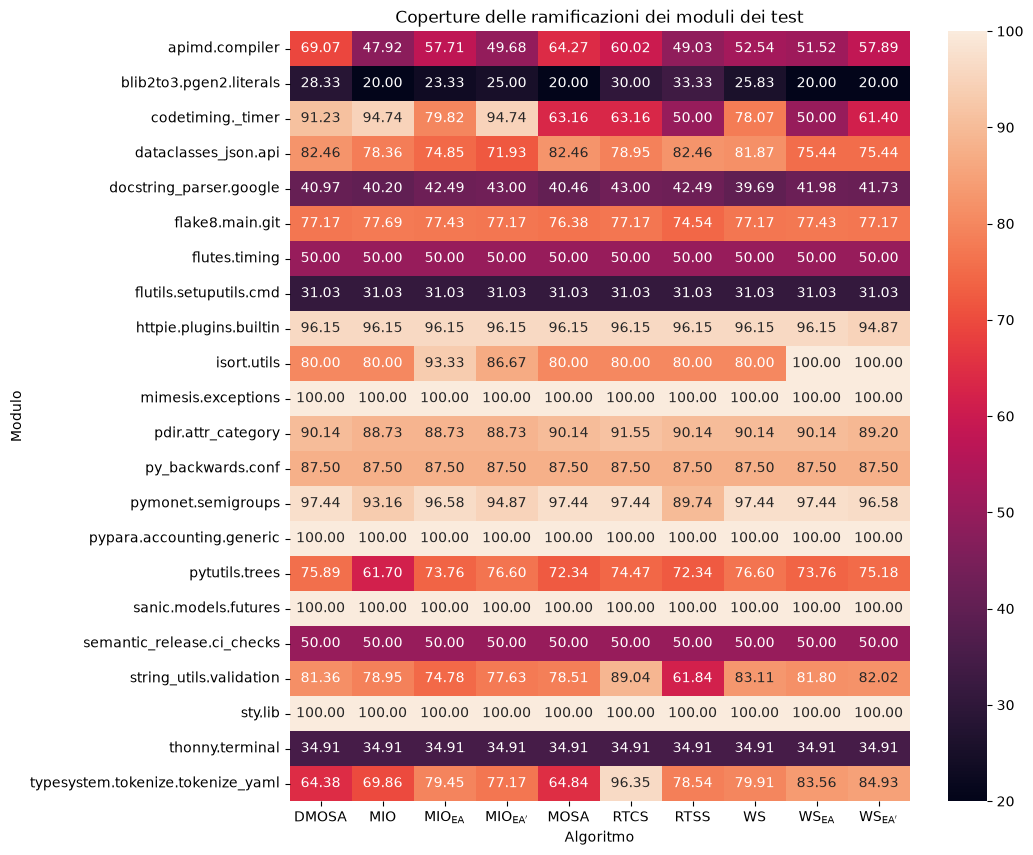

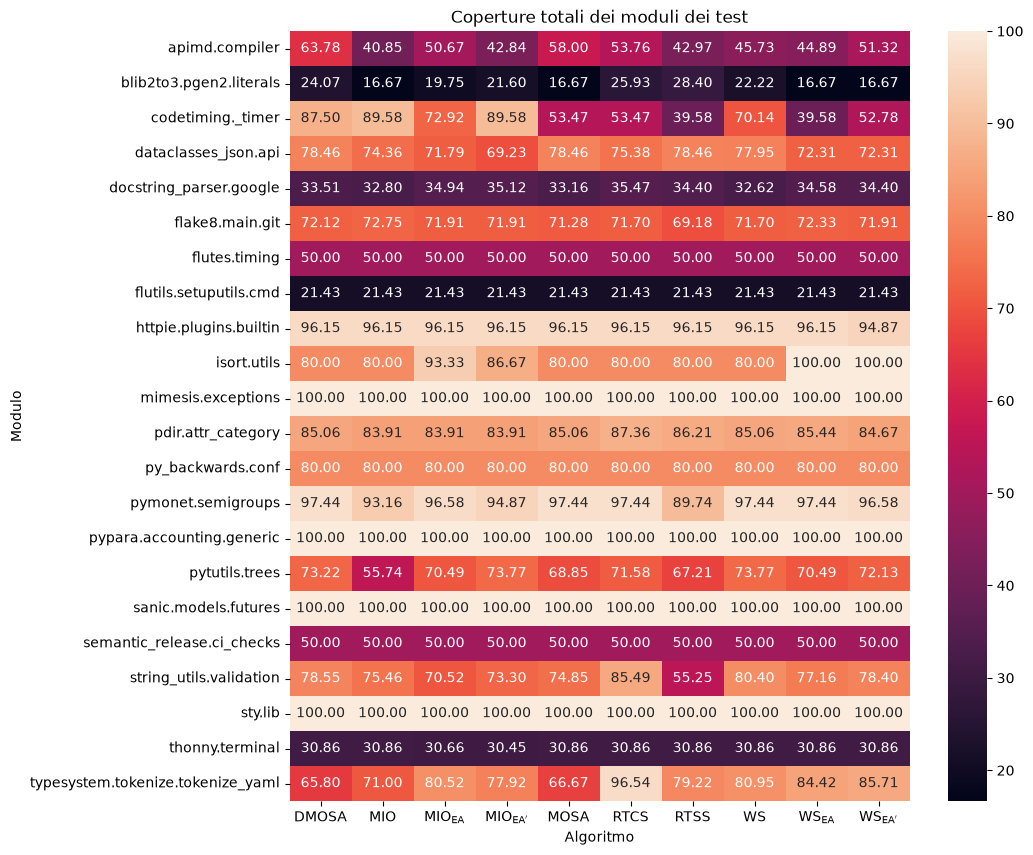

In [46]:
def coverage_plot_of_projects2(data, coverage):
    df = data[coverage]
    df.rename(columns=abbr_algorithm, inplace=True)
    match coverage:
        case 'Copertura delle ramificazioni (%)':
            part = 'Coperture delle ramificazioni'
        case 'Copertura delle istruzioni (%)':
            part = 'Coperture delle ramificazioni'
        case 'Copertura totale (%)':
            part = 'Coperture totali'
        case _:
            raise ValueError('Coverage metric not recognized.')
    title = f"{part} dei moduli dei test" 
    fig, ax = plt.subplots(figsize=(10,10))
    ax = sns.heatmap(df, annot=True, fmt='.2f')
    ax.set(title=title)
    return ax

plots = {}
# Make plots for coverages of each coverage metric
df = stats_summary.reset_index(['Algoritmo', 'Progetto']).drop('Progetto', axis=1).pivot(columns=['Algoritmo'])
for coverage in ['Copertura delle ramificazioni (%)', 'Copertura delle istruzioni (%)', 'Copertura totale (%)']:
    try:
        plots[coverage] = coverage_plot_of_projects2(df, coverage)
        match coverage:
            case 'Copertura delle ramificazioni (%)':
                part = 'branch'
            case 'Copertura delle istruzioni (%)':
                part = 'line'
            case 'Copertura totale (%)':
                part = 'total'
        plots[coverage].get_figure().savefig(IMAGES_PATH / f'heat_coverage_{part}.jpg', bbox_inches='tight')
        plt.show();
    except ValueError:
        # Ignore the value that is not an algorithm
        print(f'{coverage} was skipped because it was not recognized as a coverage metric.')
        continue
    

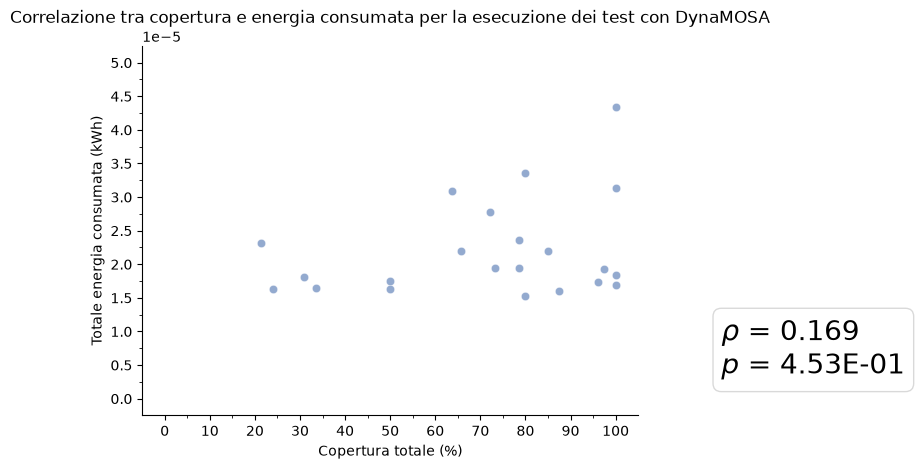

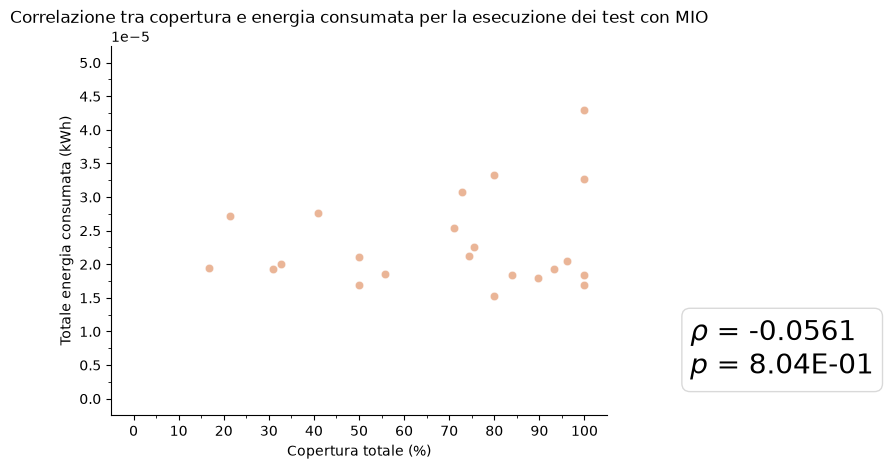

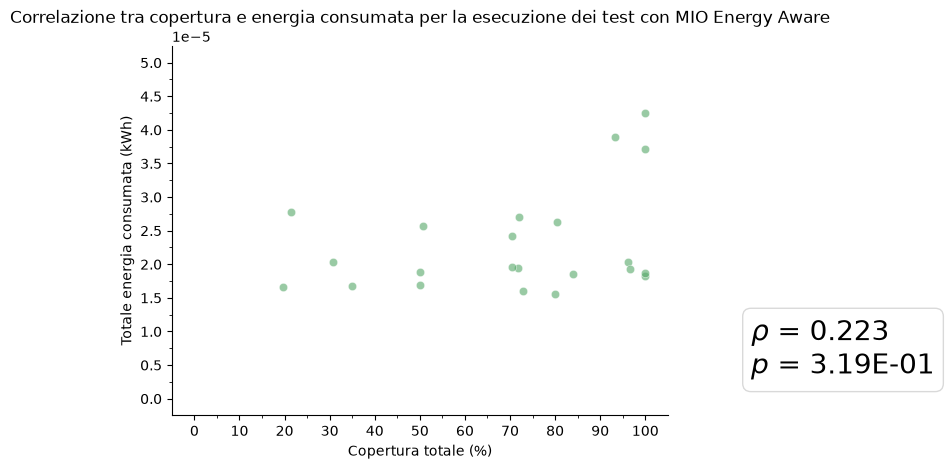

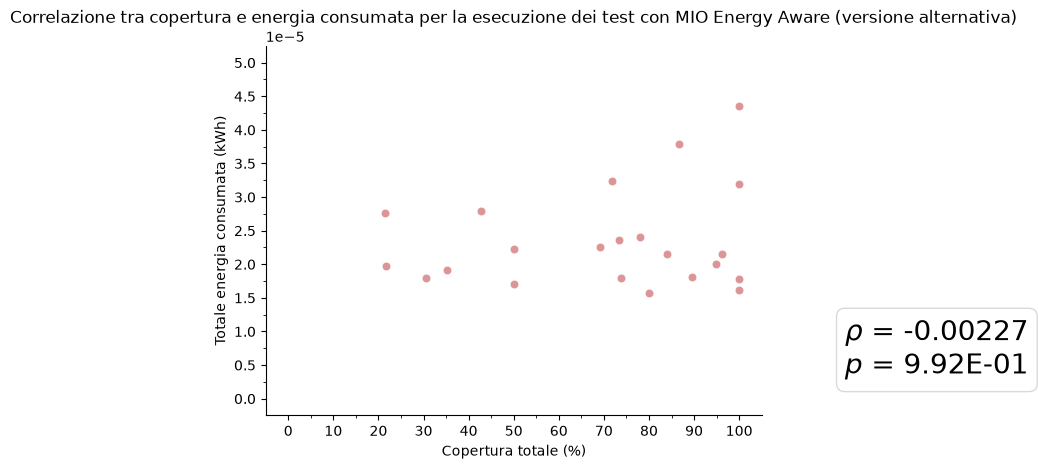

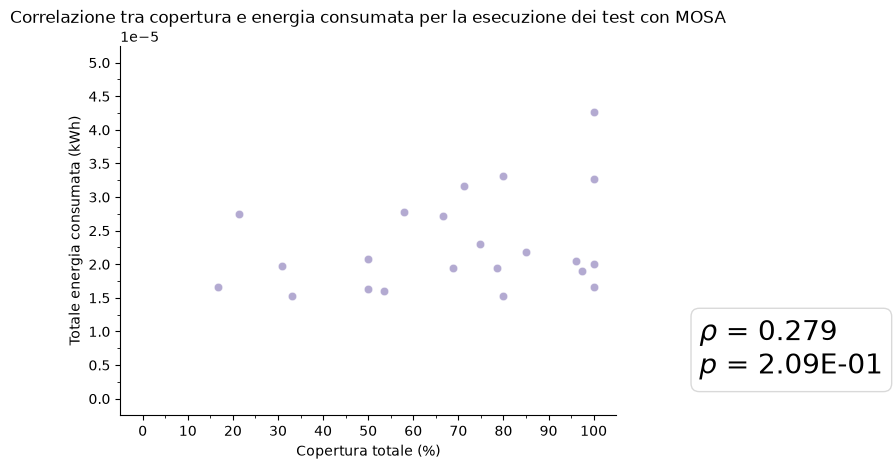

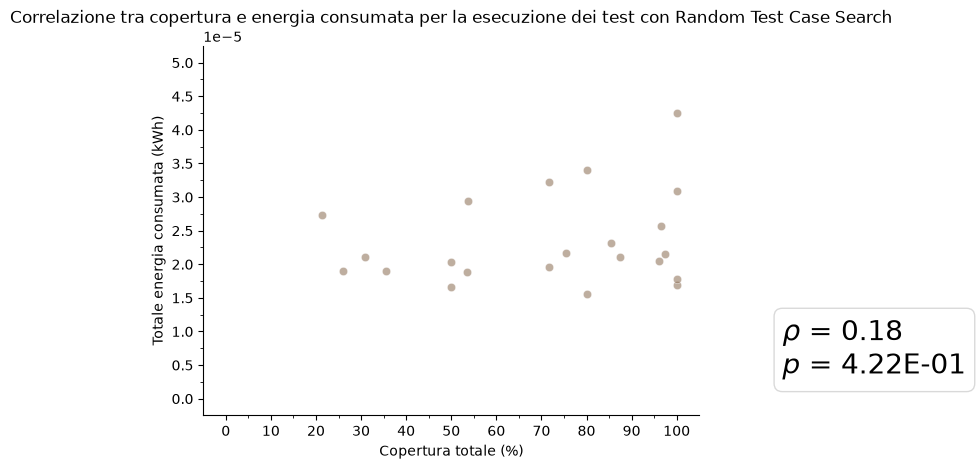

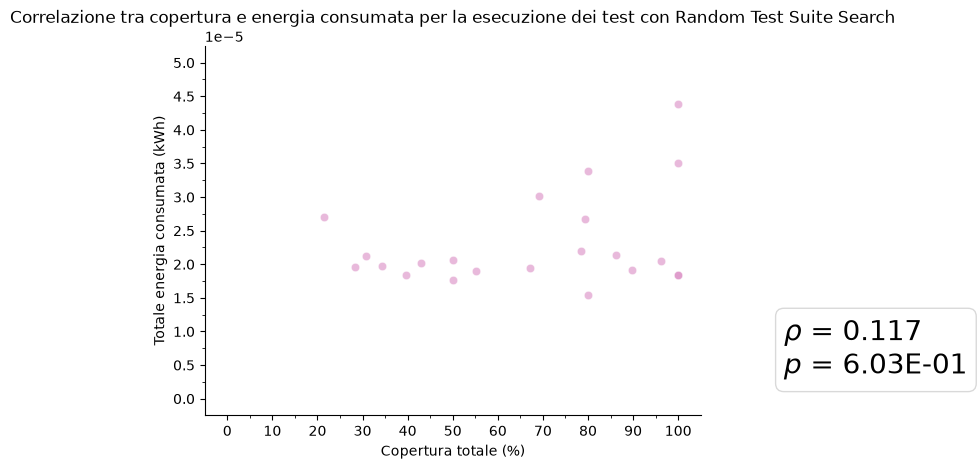

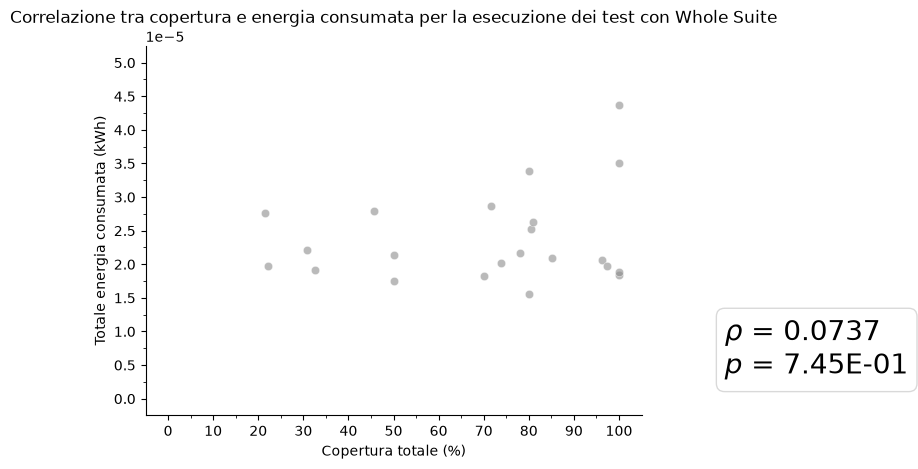

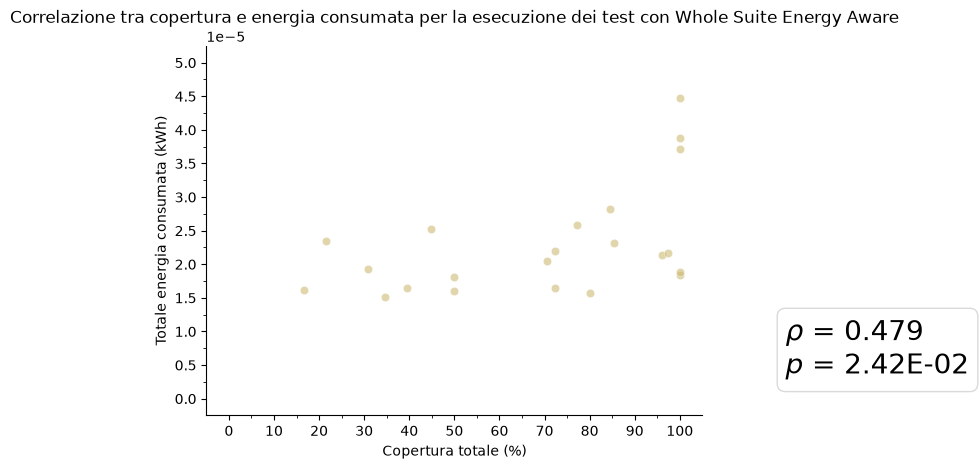

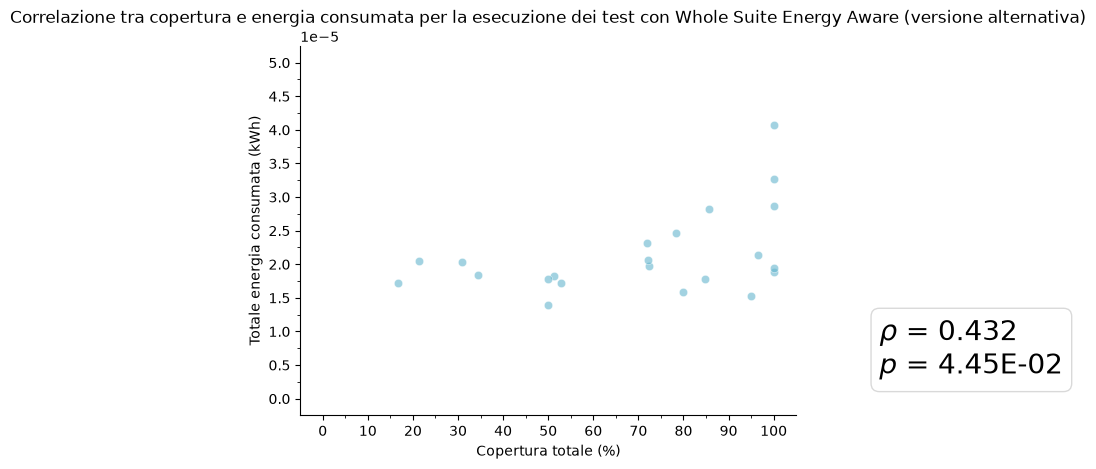

In [47]:
df = exec_summary.reset_index('Algoritmo')
col_pal = sns.color_palette('deep', len(ALGORITHMS))
for i, algorithm in enumerate(sorted(ALGORITHMS)):
    ax = plot_with_algorithms_and_regression(df[df['Algoritmo'] == algorithm],
                                             'Copertura totale (%)',
                                             'Totale energia consumata (kWh)',
                                             (0,100),
                                             (0,5e-5),
                                             5,
                                             2.5e-6,
                                             11,
                                             11,
                                             f"Correlazione tra copertura e energia consumata per la esecuzione dei test con {pretty_algorithm(algorithm)}",
                                             linregression=False,
                                             pearson=False)
    ax.get_legend().remove()
    ax.collections[0].set_facecolor(col_pal[i])
    ax.get_figure().savefig(IMAGES_PATH / f'scatter_energy_cov_{algorithm}_exec.jpg', bbox_inches='tight')
    plt.show();

In [48]:
# Per riportare le linee di codice di ciascun modulo (non cambia mai il valore tra algoritmi e iterazioni)
with COVERAGES_PATHS['DYNAMOSA'][0].open() as file:
    data = json.load(file)
    for module in data['files']:
        print(f'{module}: {data["files"][module]["summary"]["num_statements"]}')

/input/apimd/apimd/compiler.py: 361
/input/black/src/blib2to3/pgen2/literals.py: 40
/input/codetiming/codetiming/_timer.py: 38
/input/dataclasses-json/dataclasses_json/api.py: 57
/input/docstring_parser/docstring_parser/google.py: 131
/input/flake8/src/flake8/main/git.py: 127
/input/flutes/flutes/timing.py: 10
/input/flutils/flutils/setuputils/cmd.py: 58
/input/httpie/httpie/plugins/builtin.py: 26
/input/isort/isort/utils.py: 5
/input/mimesis/mimesis/exceptions.py: 32
/input/pdir2/pdir/attr_category.py: 71
/input/py-backwards/py_backwards/conf.py: 8
/input/pyMonet/pymonet/semigroups.py: 39
/input/pypara/pypara/accounting/generic.py: 8
/input/python-semantic-release/semantic_release/ci_checks.py: 56
/input/python-string-utils/string_utils/validation.py: 152
/input/pytutils/pytutils/trees.py: 47
/input/sanic/sanic/models/futures.py: 41
/input/sty/sty/lib.py: 13
/input/thonny/thonny/terminal.py: 106
/input/typesystem/typesystem/tokenize/tokenize_yaml.py: 73


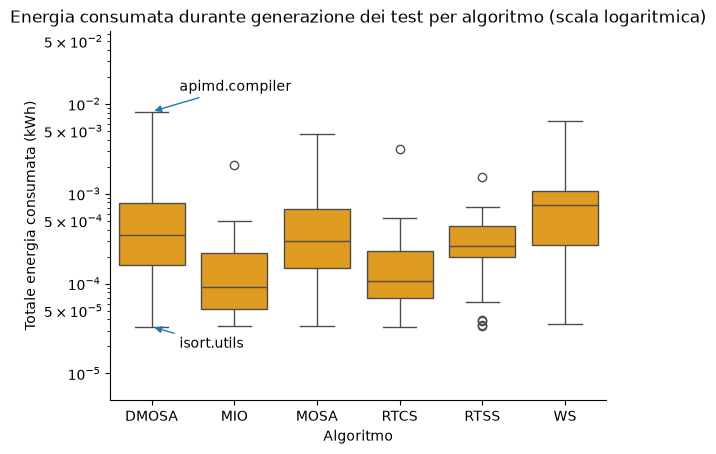

In [49]:
# Plot time
ax = boxplot_of_algorithms(fixed_gen[(fixed_gen.index.get_level_values(1) != 'MIO_ENERGY_AWARE') &
                          (fixed_gen.index.get_level_values(1) != 'MIO_ENERGY_AWARE_ALT') &
                          (fixed_gen.index.get_level_values(1) != 'WHOLE_SUITE_ENERGY_AWARE') & 
                          (fixed_gen.index.get_level_values(1) != 'WHOLE_SUITE_ENERGY_AWARE_ALT')],
                           'Totale energia consumata (kWh)',
                           log_scale=True,
                           title='Energia consumata durante generazione dei test per algoritmo (scala logaritmica)')
info1 = copy.deepcopy(info)
info1['gen']['max']['Totale energia consumata (kWh)'] = info1['gen']['max']['Totale energia consumata (kWh)'][(info1['gen']['max']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE') &
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE_ALT') &
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE') &
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE_ALT')]
info1['gen']['min']['Totale energia consumata (kWh)'] = info1['gen']['min']['Totale energia consumata (kWh)'][(info1['gen']['min']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE') &
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE_ALT') &
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE') &
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE_ALT')]
put_max_min_annotation(ax,
                       info1,
                       'gen',
                       'Totale energia consumata (kWh)',
                       (20,15),
                       (20,-15))
ax.set(ylim=(0.5e-5,6.5e-2))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1,)))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation())
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator([i * 10**j for i in range(2,10) for j in range(-2,-6,-1)]))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(log_format(-5,-1, True)))
ax.get_figure().savefig(IMAGES_PATH / 'box_gen_energy_orig.jpg', bbox_inches='tight')

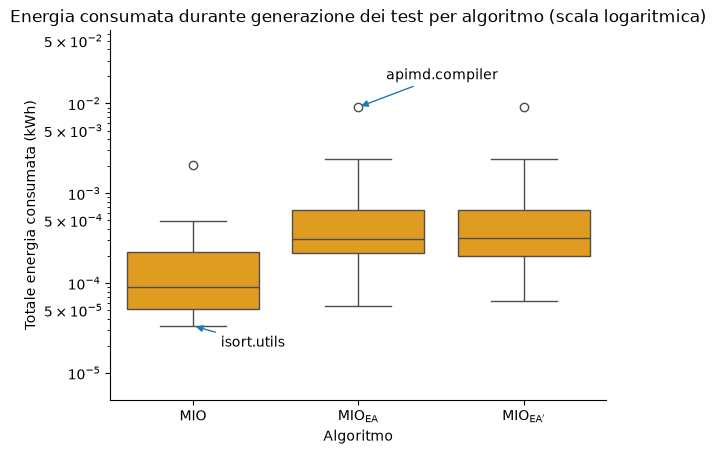

In [50]:
# Plot time
ax = boxplot_of_algorithms(fixed_gen[(fixed_gen.index.get_level_values(1) == 'MIO_ENERGY_AWARE') |
                          (fixed_gen.index.get_level_values(1) == 'MIO_ENERGY_AWARE_ALT') |
                          (fixed_gen.index.get_level_values(1) == 'MIO')],
                           'Totale energia consumata (kWh)',
                           log_scale=True,
                           title='Energia consumata durante generazione dei test per algoritmo (scala logaritmica)')
info1 = copy.deepcopy(info)
info1['gen']['max']['Totale energia consumata (kWh)'] = info1['gen']['max']['Totale energia consumata (kWh)'][(info1['gen']['max']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE') |
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE_ALT') |
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index == 'MIO')]
info1['gen']['min']['Totale energia consumata (kWh)'] = info1['gen']['min']['Totale energia consumata (kWh)'][(info1['gen']['min']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE') |
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE_ALT') |
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index == 'MIO')]
put_max_min_annotation(ax,
                       info1,
                       'gen',
                       'Totale energia consumata (kWh)',
                       (20,20),
                       (20,-15))
ax.set(ylim=(0.5e-5,6.5e-2))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1,)))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation())
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator([i * 10**j for i in range(2,10) for j in range(-2,-6,-1)]))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(log_format(-5,-1, True)))
ax.get_figure().savefig(IMAGES_PATH / 'box_gen_energy_orig_mio.jpg', bbox_inches='tight')

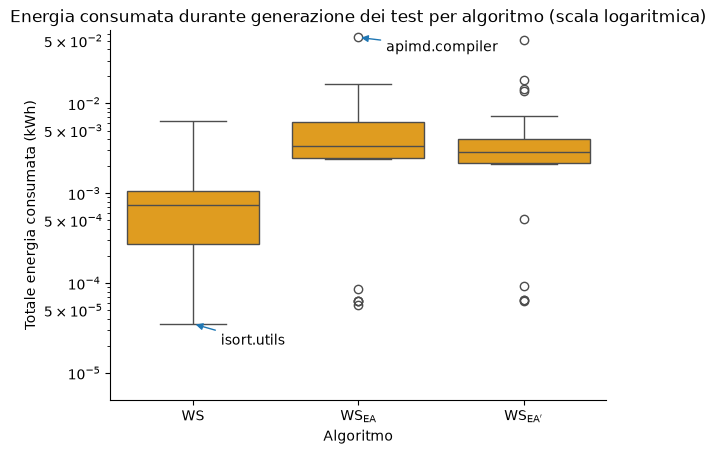

In [51]:
# Plot time
ax = boxplot_of_algorithms(fixed_gen[(fixed_gen.index.get_level_values(1) == 'WHOLE_SUITE_ENERGY_AWARE') |
                          (fixed_gen.index.get_level_values(1) == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                          (fixed_gen.index.get_level_values(1) == 'WHOLE_SUITE')],
                           'Totale energia consumata (kWh)',
                           log_scale=True,
                           title='Energia consumata durante generazione dei test per algoritmo (scala logaritmica)')
info1 = copy.deepcopy(info)
info1['gen']['max']['Totale energia consumata (kWh)'] = info1['gen']['max']['Totale energia consumata (kWh)'][(info1['gen']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE') |
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                                                                                              (info1['gen']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE')]
info1['gen']['min']['Totale energia consumata (kWh)'] = info1['gen']['min']['Totale energia consumata (kWh)'][(info1['gen']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE') |
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                                                                                              (info1['gen']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE')]
put_max_min_annotation(ax,
                       info1,
                       'gen',
                       'Totale energia consumata (kWh)',
                       (20,-10),
                       (20,-15))
ax.set(ylim=(0.5e-5,6.5e-2))
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1,)))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation())
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator([i * 10**j for i in range(2,10) for j in range(-2,-6,-1)]))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(log_format(-5,-1, True)))
ax.get_figure().savefig(IMAGES_PATH / 'box_gen_energy_orig_ws.jpg', bbox_inches='tight')

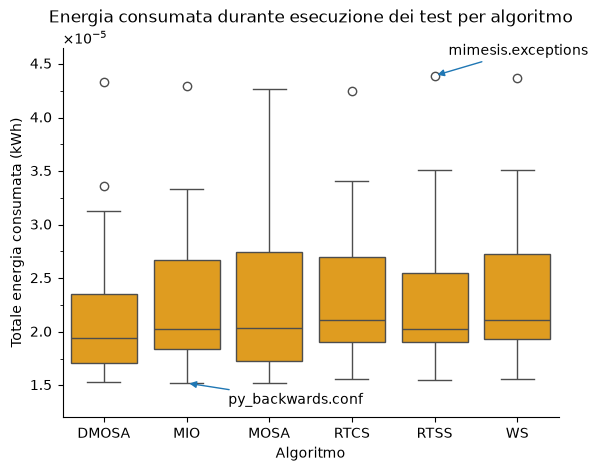

In [52]:
ax = boxplot_of_algorithms(fixed_exec[(fixed_exec.index.get_level_values(1) != 'MIO_ENERGY_AWARE') &
                          (fixed_exec.index.get_level_values(1) != 'MIO_ENERGY_AWARE_ALT') &
                          (fixed_exec.index.get_level_values(1) != 'WHOLE_SUITE_ENERGY_AWARE') & 
                          (fixed_exec.index.get_level_values(1) != 'WHOLE_SUITE_ENERGY_AWARE_ALT')],
                          'Totale energia consumata (kWh)',
                          log_scale=False,
                          title='Energia consumata durante esecuzione dei test per algoritmo')
info1 = copy.deepcopy(info)
info1['exec']['max']['Totale energia consumata (kWh)'] = info1['exec']['max']['Totale energia consumata (kWh)'][(info1['exec']['max']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE') &
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE_ALT') &
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE') &
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE_ALT')]
info1['exec']['min']['Totale energia consumata (kWh)'] = info1['exec']['min']['Totale energia consumata (kWh)'][(info1['exec']['min']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE') &
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index != 'MIO_ENERGY_AWARE_ALT') &
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE') &
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index != 'WHOLE_SUITE_ENERGY_AWARE_ALT')]
put_max_min_annotation(ax, info1, 'exec', 'Totale energia consumata (kWh)', (10,15), (30,-15))
ax.set(ylim=(1.2e-5,4.65e-5))
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(1.5e-5,5e-5,0.25e-5)))
ax.get_figure().savefig(IMAGES_PATH / 'box_exec_energy_orig.jpg', bbox_inches='tight')

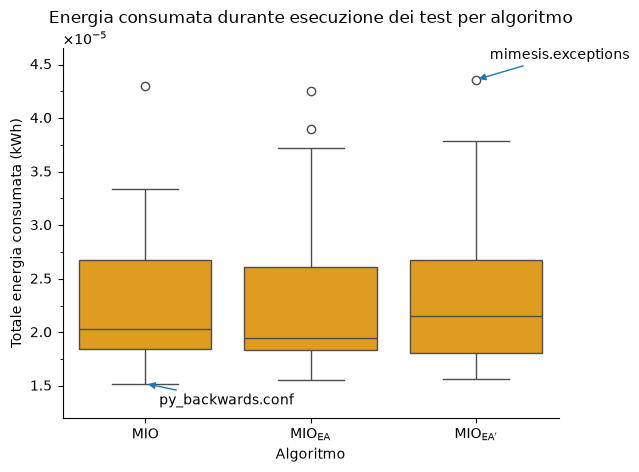

In [53]:
ax = boxplot_of_algorithms(fixed_exec[(fixed_exec.index.get_level_values(1) == 'MIO_ENERGY_AWARE') |
                          (fixed_exec.index.get_level_values(1) == 'MIO_ENERGY_AWARE_ALT') |
                          (fixed_exec.index.get_level_values(1) == 'MIO')],
                          'Totale energia consumata (kWh)',
                          log_scale=False,
                          title='Energia consumata durante esecuzione dei test per algoritmo')
info1 = copy.deepcopy(info)
info1['exec']['max']['Totale energia consumata (kWh)'] = info1['exec']['max']['Totale energia consumata (kWh)'][(info1['exec']['max']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE') |
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE_ALT') |
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index == 'MIO')]
info1['exec']['min']['Totale energia consumata (kWh)'] = info1['exec']['min']['Totale energia consumata (kWh)'][(info1['exec']['min']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE') |
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index == 'MIO_ENERGY_AWARE_ALT') |
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index == 'MIO')]
put_max_min_annotation(ax, info1, 'exec', 'Totale energia consumata (kWh)', (10,15), (10,-15))
ax.set(ylim=(1.2e-5,4.65e-5))
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(1.5e-5,5e-5,0.25e-5)))
ax.get_figure().savefig(IMAGES_PATH / 'box_exec_energy_mio.jpg', bbox_inches='tight')

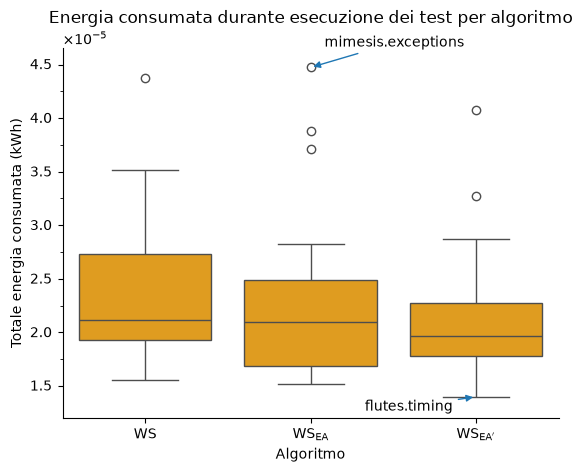

In [54]:
ax = boxplot_of_algorithms(fixed_exec[(fixed_exec.index.get_level_values(1) == 'WHOLE_SUITE_ENERGY_AWARE') |
                          (fixed_exec.index.get_level_values(1) == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                          (fixed_exec.index.get_level_values(1) == 'WHOLE_SUITE')],
                          'Totale energia consumata (kWh)',
                          log_scale=False,
                          title='Energia consumata durante esecuzione dei test per algoritmo')
info1 = copy.deepcopy(info)
info1['exec']['max']['Totale energia consumata (kWh)'] = info1['exec']['max']['Totale energia consumata (kWh)'][(info1['exec']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE') |
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                                                                                                (info1['exec']['max']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE')]
info1['exec']['min']['Totale energia consumata (kWh)'] = info1['exec']['min']['Totale energia consumata (kWh)'][(info1['exec']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE') |
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                                                                                                (info1['exec']['min']['Totale energia consumata (kWh)'].index == 'WHOLE_SUITE')]
ax.set(ylim=(1.2e-5,4.65e-5))
put_max_min_annotation(ax, info1, 'exec', 'Totale energia consumata (kWh)', (10,15), (-80,-10))
ax.yaxis.set_major_formatter(mpl.ticker.ScalarFormatter(useMathText=True))
ax.yaxis.set_minor_locator(mpl.ticker.FixedLocator(np.arange(1.5e-5,5e-5,0.25e-5)))
ax.get_figure().savefig(IMAGES_PATH / 'box_exec_energy_ws.jpg', bbox_inches='tight')

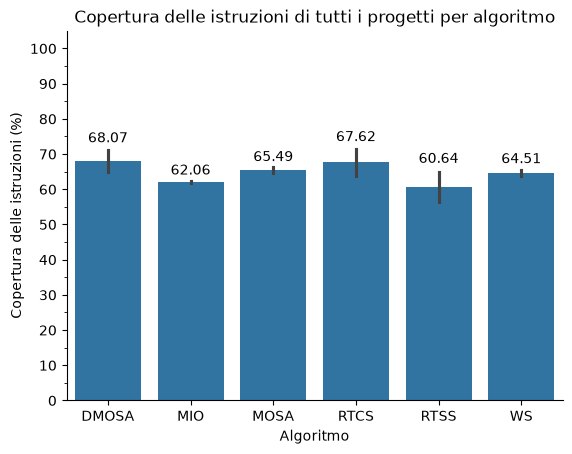

In [55]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE_ALT') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE_ALT')],
                            'Copertura delle istruzioni (%)',
                            [11,3,4,13,15,5],
                            'Copertura delle istruzioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_statements_orig.jpg', bbox_inches='tight')

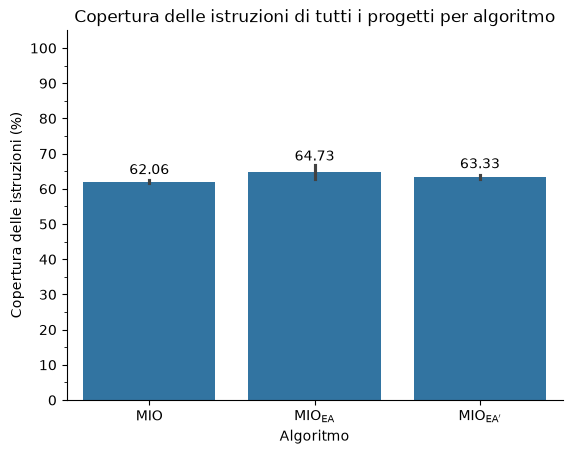

In [56]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO')],
                            'Copertura delle istruzioni (%)',
                            [3,6,4],
                            'Copertura delle istruzioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_statements_mio.jpg', bbox_inches='tight')

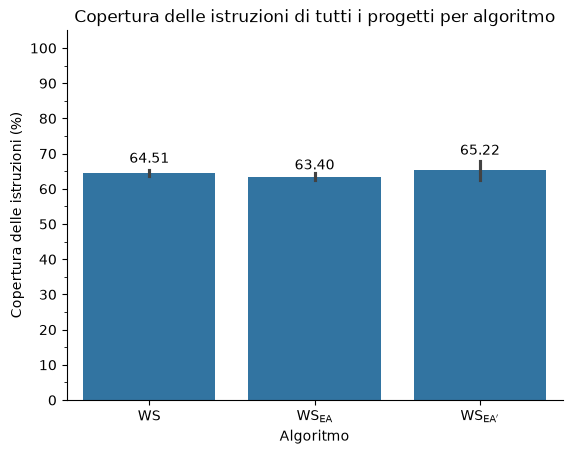

In [57]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE')],
                            'Copertura delle istruzioni (%)',
                            [5,3,9],
                            'Copertura delle istruzioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_statements_ws.jpg', bbox_inches='tight')

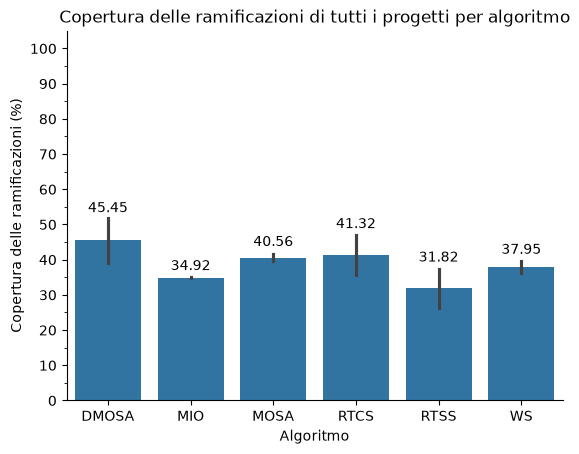

In [58]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE_ALT') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE_ALT')],
                            'Copertura delle ramificazioni (%)',
                            [18,3,6,17,17,7],
                            'Copertura delle ramificazioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_branches_orig.jpg', bbox_inches='tight')

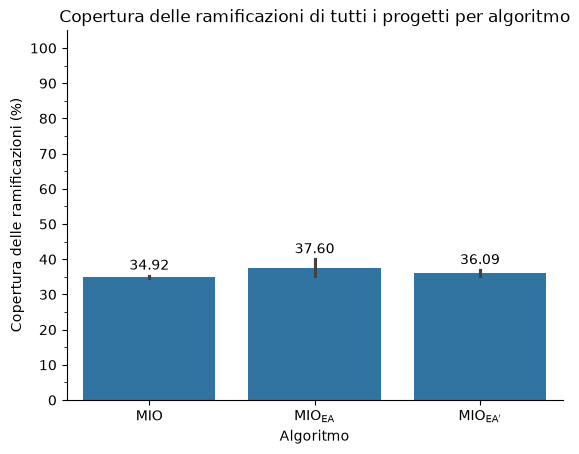

In [59]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO')],
                            'Copertura delle ramificazioni (%)',
                            [3,8,4],
                            'Copertura delle ramificazioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_branches_mio.jpg', bbox_inches='tight')

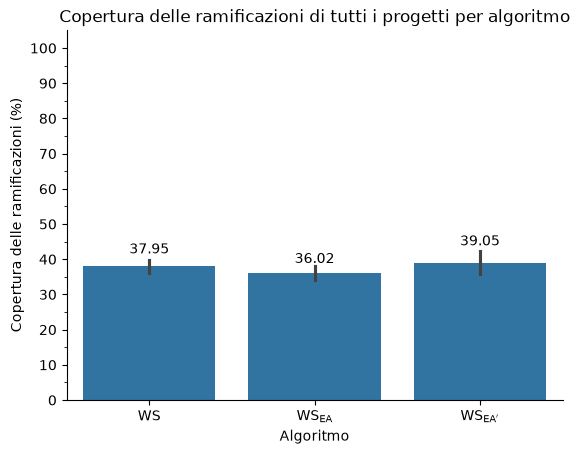

In [60]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE')],
                            'Copertura delle ramificazioni (%)',
                            [7,5,10],
                            'Copertura delle ramificazioni di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_branches_ws.jpg', bbox_inches='tight')

In [61]:
# 3,7,2
# 7,5,8

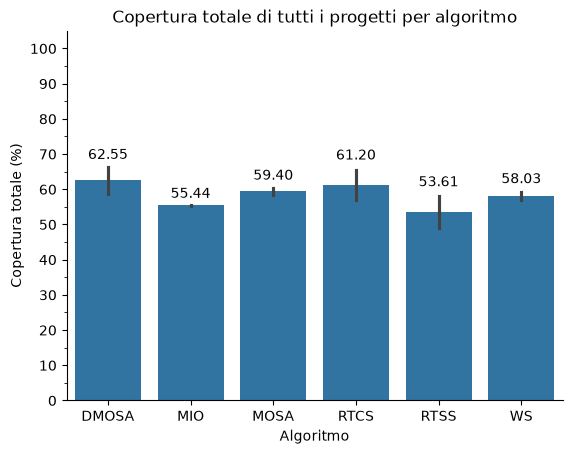

In [62]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'MIO_ENERGY_AWARE_ALT') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE') &
                                         (fixed_totals.index.get_level_values(0) != 'WHOLE_SUITE_ENERGY_AWARE_ALT')],
                            'Copertura totale (%)',
                            [13,3,6,16,16,7],
                            'Copertura totale di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_total_orig.jpg', bbox_inches='tight')

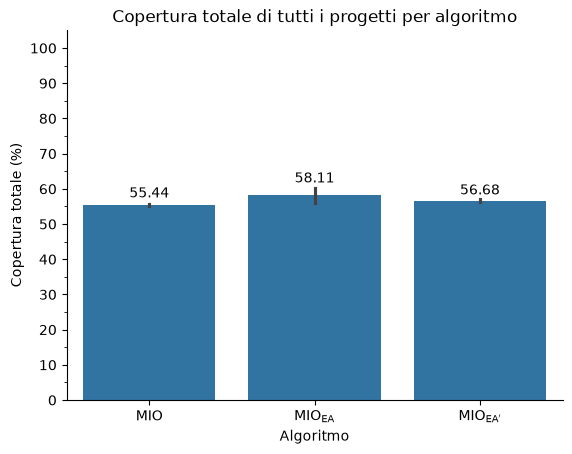

In [63]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'MIO')],
                            'Copertura totale (%)',
                            [3,7,2],
                            'Copertura totale di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_total_mio.jpg', bbox_inches='tight')

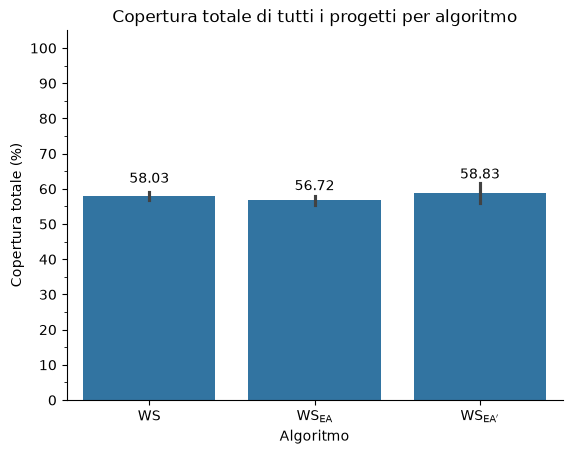

In [64]:
ax = coverage_of_algorithms(fixed_totals[(fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE_ENERGY_AWARE_ALT') |
                                         (fixed_totals.index.get_level_values(0) == 'WHOLE_SUITE')],
                            'Copertura totale (%)',
                            [7,5,8],
                            'Copertura totale di tutti i progetti per algoritmo')
ax.get_figure().savefig(IMAGES_PATH / 'bar_coverage_total_ws.jpg', bbox_inches='tight')